# Лабораторная работа № 1. Современный парсинг динамических веб-сайтов: Playwright и Selenium в Google Colab

**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Среда:** Google Colab (Chromium в headless-режиме) · до 10 баллов

## Цель

Освоить управление headless-браузером для сбора данных с сайтов, где содержимое рисует JavaScript, и довести собранное до управленческого вывода.

## Задачи

1. Понять, почему `requests` и `BeautifulSoup` бессильны против SPA на React, Angular и Vue, и научиться отличать серверный рендеринг от клиентского.
2. Развернуть в Colab headless-Chromium (Playwright как основной движок, Selenium как альтернативный) с корректными флагами безопасности.
3. Отработать обход препятствий: cookie-баннеры и модальные окна, отложенная гидратация, догрузка по кнопке и прокрутке.
4. Писать устойчивые XPath-выражения: предикаты, функции `contains()`, `text()`, `starts-with()`, `translate()`, поиск по `data-testid`.
5. Заменить `time.sleep()` явными ожиданиями (`wait_for_selector`, `wait_for_function`, `WebDriverWait`).
6. Очистить числовые признаки с суффиксами (`30.5M`, `1.23B`, `870K`), процентами (`+2.5%`, `−1,8%`) и валютой, выгрузить результат в Excel.
7. Построить продуктовую аналитику: топы, распределения, когорты роста и падения — и сформулировать решение для ЛПР.

## Что сдаётся

Ноутбук **с сохранёнными выводами ячеек**, файл Excel и скриншот целевой страницы (доказательство сбора), опубликованные в личном репозитории GitHub. В LMS сдаётся ссылка на репозиторий.

## Как устроена работа и как её выполнять

### Обязательная часть — учебный стенд

Работа выполняется на **учебном стенде**, который ноутбук поднимает сам: это одностраничное приложение с cookie-баннером, отложенной отрисовкой через JavaScript и подгрузкой по кнопке «Показать ещё». У каждого варианта свой профиль данных и свой набор чисел, привязанный к номеру варианта.

Почему не сразу «боевой» сайт:

* стенд воспроизводим — он ведёт себя одинаково на защите и через полгода;
* он содержит ровно те препятствия, ради которых нужен браузер, и ничего лишнего;
* его разрешено парсить: он ваш собственный.

### Вторая часть — реальная площадка

В таблице вариантов указана реальная бизнес-площадка (CoinMarketCap, Investing.com, Yahoo Finance, Trading Economics и другие). С ней работа **исследовательская**: открыть `robots.txt` и пользовательское соглашение, определить, разрешён ли автоматический сбор, найти в панели «Сеть» браузера XHR-запрос с данными и указать легальный источник тех же данных (столбец «Легальный источник»). Включать режим `USE_LIVE_TARGET` можно только если преподаватель разрешил это для вашей площадки и её правила не запрещают автоматические обращения.

Что делать нельзя ни при каких обстоятельствах: обходить капчу и защиту Cloudflare, использовать stealth-плагины для маскировки под человека, снимать данные за логином и собирать персональные данные. Это выходит за рамки учебной задачи и нарушает правила площадок и 152-ФЗ.

### Порядок работы

1. **Файл → Сохранить копию на Диске.**
2. В шаге 1 выставьте номер варианта. Параметры подставятся автоматически.
3. Выполняйте ячейки сверху вниз. Перед каждым шагом — методическое обоснование, после — интерпретация результата.
4. Места с пометкой `TODO` дописываете вы; до этого ячейка падает с `NotImplementedError` — так и задумано.
5. Перед сдачей запустите самопроверку: должно быть «Выполнено: 11 из 11».

### Особенность Colab

В Colab уже работает цикл событий `asyncio`, поэтому синхронный API Playwright выдаст ошибку «It looks like you are using Playwright Sync API inside the asyncio loop». В работе используется **асинхронный API** и `await` прямо в ячейке; `nest_asyncio` подключён на случай вложенных запусков. Установка Chromium занимает 30–60 секунд и выполняется один раз за сессию.

## Теоретический блок 1. Почему статический парсинг бессилен

### Два способа доставить страницу пользователю

| | Server-Side Rendering | Client-Side Rendering (SPA) |
|---|---|---|
| Что приходит в ответ на GET | готовый HTML с данными | «скелет»: пустой `<div id="root">` и ссылки на бандлы |
| Где берутся данные | сервер собрал их до отправки | браузер выполняет JS, тот запрашивает JSON и строит DOM |
| Что увидит `requests` | данные | пустой каркас |
| Типичный стек | Django, Rails, классический PHP | React, Angular, Vue, Svelte |

**Гидратация** — момент, когда загруженный JavaScript «оживляет» разметку и подставляет данные. До неё в DOM нужных узлов физически нет. В нашем стенде это видно буквально: в исходном HTML ноль строк таблицы, а после гидратации их двенадцать.

### Как отличить одно от другого за 15 секунд

1. `view-source:` или `requests.get(url).text` — есть ли в ответе искомое число?
2. Если нет — открыть DevTools → вкладка **Network** → фильтр **Fetch/XHR** и перезагрузить страницу. Часто данные приходят одним JSON-запросом: тогда браузер не нужен вовсе, достаточно обратиться к этому эндпоинту (это самый быстрый и устойчивый путь).
3. Если данные собираются множеством запросов, приходят в зашифрованном виде или защищены проверкой браузера — нужен headless-браузер.

### Что ещё ломает наивный сбор

* **Отложенная подгрузка**: бесконечная прокрутка, кнопки «Показать ещё», ленивые изображения.
* **Оверлеи**: cookie-баннеры, модальные окна о регионе и подписке — они перекрывают клики.
* **Проверки браузера**: Cloudflare и подобные системы выполняют JS-challenge и проверяют отпечаток клиента. Их обход — не учебная задача: если площадка явно не хочет автоматических обращений, аналитик ищет официальный API или лицензированного поставщика данных.
* **Разметка без смысловых якорей**: сгенерированные классы вида `css-1x7ab3e`. Опора на такие классы — гарантированная поломка после следующего релиза.

### Экономика вопроса

Браузер дороже HTTP-запроса в десятки раз: запуск процесса, рендеринг, исполнение JS. Поэтому порядок выбора инструмента такой: **официальный API → скрытый JSON-эндпоинт → HTML без JS → headless-браузер**. Браузер — последний рубеж, а не первый.

## Теоретический блок 2. Selenium против Playwright

| Критерий | Selenium 4.x | Playwright 1.x |
|---|---|---|
| Протокол | W3C WebDriver: скрипт → драйвер → браузер | CDP (Chrome DevTools Protocol) напрямую, один WebSocket |
| Установка браузера | Chrome ставится отдельно, драйвер подбирает Selenium Manager | `playwright install chromium` кладёт совместимую сборку |
| Ожидания | неявные (`implicitly_wait`) и явные (`WebDriverWait` + `expected_conditions`) | автоожидание в каждом действии + явные `wait_for_selector` / `wait_for_function` |
| Асинхронность | синхронный API (есть сторонние обёртки) | синхронный и асинхронный API; в Jupyter обязателен асинхронный |
| Изоляция | новый профиль или новый браузер | `browser_context` — «инкогнито» за миллисекунды, десятки контекстов на один браузер |
| Сеть | перехват ограничен | `page.route()`: блокировка картинок, подмена ответов, чтение XHR |
| Скорость на типовом сценарии | ниже: лишний сетевой слой драйвера и ручные ожидания | выше: меньше слоёв, автоожидание убирает «сон на всякий случай» |
| Экосистема | огромная, много легаси-кода и примеров | моложе, документация лучше, API современнее |

**Практический вывод.** Для новых проектов сбора данных берут Playwright: меньше кода, меньше «плавающих» падений, дешевле параллелизм (контексты вместо браузеров). Selenium остаётся там, где он уже внедрён, нужен конкретный браузер или инфраструктура Selenium Grid. В этой работе основной путь — Playwright, а Selenium приведён как альтернативный движок: важно уметь читать и то, и другое.

### Один и тот же сценарий на двух движках

```python
# Playwright (async)                        | # Selenium (sync)
await page.goto(url)                        # driver.get(url)
await page.wait_for_selector("xpath=//tr")  # WebDriverWait(driver, 15).until(
                                            #     EC.presence_of_element_located((By.XPATH, "//tr")))
await page.click("xpath=//button[@id='m']") # driver.find_element(By.XPATH, "//button[@id='m']").click()
html = await page.content()                 # html = driver.page_source
await browser.close()                       # driver.quit()
```

### Флаги запуска в контейнере Colab

| Флаг | Зачем |
|---|---|
| `--no-sandbox` | в контейнере нет нужных namespace, без флага Chromium не стартует |
| `--disable-dev-shm-usage` | `/dev/shm` в контейнере мал; без флага падение на тяжёлых страницах |
| `--disable-gpu` | GPU в headless не нужен |
| `--window-size=1440,900` | фиксируем окно: адаптивная вёрстка не «схлопнет» таблицу в карточки |
| `user_agent` | заголовок клиента; в учебной работе он честный, с пометкой о проекте |

## Теоретический блок 3. Шпаргалка по XPath

### Основы

| Выражение | Что делает |
|---|---|
| `//div` | все `div` на любом уровне |
| `//div/span` | `span` — прямой потомок `div` |
| `.//td` | потомки **текущего** узла (точка обязательна при поиске внутри строки) |
| `//*[@id="root"]` | элемент по атрибуту |
| `//td/@data-value` | значение атрибута |
| `//td/text()` | текстовый узел |
| `//tr[3]` | третья строка (нумерация с единицы) |
| `//tr[last()]`, `//tr[position() <= 5]` | последняя строка, первые пять |

### Функции, без которых не обойтись

| Функция | Пример | Смысл |
|---|---|---|
| `contains()` | `//div[contains(@class, "product")]` | класс среди нескольких: `class="card product new"` |
| `starts-with()` | `//tr[starts-with(@id, "row-")]` | префикс идентификатора |
| `text()` | `//th[text()="UPC"]` | точное совпадение текста узла |
| `normalize-space()` | `//td[normalize-space()="В наличии"]` | сравнение без лишних пробелов |
| `translate()` | `//button[contains(translate(., "ПРИНЯТЬ", "принять"), "принять")]` | сравнение без учёта регистра (в XPath 1.0 нет `lower-case()`) |
| `count()` | `count(//tr[@data-testid="asset-row"])` | сколько узлов — удобно в условии ожидания |

### Оси: движение по дереву

| Ось | Пример | Когда нужна |
|---|---|---|
| `following-sibling::` | `//th[text()="Объём"]/following-sibling::td[1]` | «ячейка справа от подписи» — таблицы характеристик |
| `preceding-sibling::` | `//td[@class="val"]/preceding-sibling::th` | найти подпись по значению |
| `parent::` / `..` | `//span[@class="price"]/parent::div` | подняться к карточке товара |
| `ancestor::` | `//a[@data-id="7"]/ancestor::tr` | строка таблицы, в которой лежит ссылка |

### Почему `data-testid` — лучший якорь

Классы вида `css-1x7ab3e` генерирует сборщик стилей: они меняются при каждом релизе. Атрибуты `data-testid`, `data-qa`, `data-cy` ставят разработчики для собственных автотестов, и ломать их себе дороже. Отсюда порядок надёжности селекторов:

```
data-testid  →  семантический атрибут (id, name, aria-label)  →  структура (tag + contains(@class))  →  текст  →  позиция
   надёжно                                                                                              хрупко
```

### Типичные ошибки

1. Забытая точка: внутри строки `//td` ищет по всему документу, а не в строке. Нужно `.//td`.
2. `text()` возвращает **список** текстовых узлов; если внутри есть вложенные теги, берите `string(.)` или `normalize-space(.)`.
3. Слишком длинный путь `/html/body/div[2]/div[3]/table/tbody/tr` — сломается от любой вставки блока.
4. `tbody`, которого нет в исходном HTML: браузер добавляет его сам, и XPath, скопированный из DevTools, не сработает на «сыром» HTML.

## Теоретический блок 4. Стратегии ожидания

Главная причина «плавающих» падений парсера — попытка прочитать элемент раньше, чем он появился.

| Стратегия | Как выглядит | Оценка |
|---|---|---|
| `time.sleep(5)` | «подождём на всякий случай» | Плохо: на быстрой сети теряем время, на медленной всё равно падаем |
| Неявное ожидание (`implicitly_wait`) | Selenium ждёт появления элемента до N секунд | Приемлемо как страховка, но не различает «нет элемента» и «элемент пустой» |
| Явное ожидание | `WebDriverWait(driver, 15).until(EC.presence_of_element_located(...))`, `page.wait_for_selector(...)` | Правильно: ждём конкретного условия |
| Ожидание предиката | `page.wait_for_function("() => document.querySelectorAll('tr').length > 12")` | Лучшее для догрузки: ждём **роста числа строк**, а не просто появления первой |
| Ожидание сети | `wait_until="networkidle"` | Осторожно: на страницах с постоянными опросами (poll) никогда не наступит |

### Важные различия

* `presence_of_element_located` — элемент есть в DOM; `visibility_of_element_located` — он ещё и виден. Кликать можно только по видимому и не перекрытому элементу — отсюда правило: **сначала закрыть баннер, потом кликать**.
* В Playwright автоожидание встроено в действия: `click()` сам дождётся видимости и стабильности элемента. Это не отменяет явных ожиданий там, где вы ждёте не элемент, а **состояние данных** (например, что строк стало больше).
* Любое ожидание конечно. Таймаут должен приводить не к падению всего ноутбука, а к понятному сообщению плюс сохранённым скриншоту и HTML — это артефакты для разбора.

```python
try:
    await page.wait_for_selector("xpath=//tr[@data-testid='asset-row']", timeout=30000)
except PWTimeout:
    await page.screenshot(path="timeout.png", full_page=True)
    Path("timeout.html").write_text(await page.content())
    raise RuntimeError("Строки не появились: проверьте XPath и вёрстку — артефакты сохранены")
```

### Шаг 1. Развёртывание зависимостей

**Методическое обоснование.** Colab — это одноразовый контейнер: браузера в нём нет, а после отключения среды всё исчезает. Поэтому первая ячейка разворачивает окружение заново и делает это идемпотентно — повторный запуск не переустанавливает то, что уже стоит. Здесь же выбирается движок и задаются параметры варианта.

In [12]:
#@title Шаг 1. Развёртывание окружения и параметры варианта { display-mode: "form" }
VARIANT = 17                 #@param {type:"slider", min:1, max:30, step:1}
ENGINE = "playwright"        #@param ["playwright", "selenium"]
HEADLESS = True              #@param {type:"boolean"}
USE_LIVE_TARGET = False      #@param {type:"boolean"}
NAV_TIMEOUT_MS = 30000       #@param {type:"slider", min:5000, max:60000, step:5000}
BLOCK_HEAVY_RESOURCES = True #@param {type:"boolean"}

import asyncio, functools, importlib, io, json, math, os, random, re, shutil, socket
import subprocess, sys, textwrap, threading, time, warnings
from datetime import datetime
from pathlib import Path

def sh(cmd, tail=400):
    """Выполняем системную команду и показываем только хвост вывода."""
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    out = (r.stdout + r.stderr).strip()
    if out:
        print(out[-tail:])
    return r.returncode == 0

def ensure(pkg, module=None):
    try:
        importlib.import_module(module or pkg)
        return True
    except ImportError:
        sh(f"{sys.executable} -m pip install -q {pkg}")
        importlib.invalidate_caches()
        try:
            importlib.import_module(module or pkg)
            return True
        except ImportError:
            return False

for pkg, mod in [("pandas", "pandas"), ("matplotlib", "matplotlib"), ("seaborn", "seaborn"),
                 ("lxml", "lxml"), ("openpyxl", "openpyxl"), ("nest_asyncio", "nest_asyncio")]:
    ensure(pkg, mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from lxml import html as lxml_html
try:                          # Colab уже крутит цикл событий: разрешаем вложенный запуск
    import nest_asyncio
    nest_asyncio.apply()
except Exception:
    pass                      # без nest_asyncio ячейки с await тоже работают

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})
pd.set_option("display.width", 170, "display.max_columns", 40)

# ----------------------------------------------------------------- Playwright
if ENGINE == "playwright":
    ensure("playwright", "playwright")
    from playwright.async_api import async_playwright, TimeoutError as PWTimeout
    # браузер ставится один раз: ~120 МБ, 30-60 секунд
    try:
        from playwright._impl._driver import compute_driver_executable  # noqa: F401
        need_install = not any(Path(p).exists() for p in
                               [os.environ.get("PLAYWRIGHT_BROWSERS_PATH", ""), Path.home() / ".cache/ms-playwright"]
                               if p)
    except Exception:
        need_install = True
    probe = subprocess.run([sys.executable, "-c",
                            "from playwright.sync_api import sync_playwright;"
                            "p=sync_playwright().start();print(p.chromium.executable_path);p.stop()"],
                           capture_output=True, text=True)
    browser_path = probe.stdout.strip().splitlines()[-1] if probe.returncode == 0 and probe.stdout.strip() else ""
    if not browser_path or not Path(browser_path).exists():
        print("Ставим Chromium для Playwright (это делается один раз за сессию)…")
        sh(f"{sys.executable} -m playwright install --with-deps chromium")
    else:
        print(f"Chromium уже установлен: {browser_path}")

# ----------------------------------------------------------------- Selenium (альтернативный путь)
if ENGINE == "selenium":
    ensure("selenium", "selenium")
    if not shutil.which("google-chrome") and not shutil.which("chromium"):
        print("Ставим Google Chrome (Selenium Manager сам подберёт драйвер)…")
        sh("wget -q https://dl.google.com/linux/direct/google-chrome-stable_current_amd64.deb "
           "-O /tmp/chrome.deb && apt-get -qq install -y /tmp/chrome.deb")
    import selenium
    from selenium import webdriver
    from selenium.webdriver.common.by import By
    from selenium.webdriver.support.ui import WebDriverWait
    from selenium.webdriver.support import expected_conditions as EC
    from selenium.common.exceptions import TimeoutException, NoSuchElementException
    print("Selenium:", selenium.__version__, "| Chrome:", shutil.which("google-chrome"))

UA = ("Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) "
      "Chrome/141.0.0.0 Safari/537.36 (educational project, MGPU BI)")
WORK_DIR = Path("/content/lr1" if Path("/content").exists() else "lr1_work")
WORK_DIR.mkdir(parents=True, exist_ok=True)

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

print(f"\nДвижок: {ENGINE} | headless: {HEADLESS} | таймаут навигации: {NAV_TIMEOUT_MS} мс")
print(f"Рабочая папка: {WORK_DIR} | pandas {pd.__version__} | seaborn {sns.__version__}")

Chromium уже установлен: /root/.cache/ms-playwright/chromium-1248/chrome-linux64/chrome

Движок: playwright | headless: True | таймаут навигации: 30000 мс
Рабочая папка: /content/lr1 | pandas 2.2.3 | seaborn 0.13.2


**Интерпретация.** В выводе должны быть версии библиотек и путь к Chromium. Если установка браузера запускалась, повторный запуск ячейки уже её пропустит. Выбор `ENGINE = "selenium"` дополнительно ставит Google Chrome (около минуты) — это резервный путь, основной сценарий работы построен на Playwright.

### Шаг 1.1–1.2. Вариант и учебный стенд

**Методическое обоснование.** Стенд поднимается локально (`http.server` в фоновом потоке) и служит воспроизводимым полигоном: cookie-баннер, задержка гидратации, догрузка по кнопке, «грязные» значения. Сразу после запуска ноутбук показывает главный аргумент работы: в исходном HTML строк данных **ноль**, то есть `requests` здесь бесполезен.

In [13]:
#@title Шаг 1.1. Параметры варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"domain": "Криптовалютный арбитраж",
"profile": "crypto",
"live": "CoinMarketCap — раздел Cryptocurrencies",
"live_url": "https://coinmarketcap.com/",
"api": "CoinGecko API (/coins/markets)",
"task": "Собрать витрину «Криптовалютный арбитраж» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ-10 по обороту, разброс суточного изменения; решение: где держать лимиты маркет-мейкера",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 2,
"domain": "Фондовые индексы АТР",
"profile": "stocks",
"live": "Investing.com — Asia/Pacific indices",
"live_url": "https://www.investing.com/indices/asian-indices",
"api": "MOEX ISS API, Alpha Vantage",
"task": "Собрать витрину «Фондовые индексы АТР» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Сравнение доходностей, когорты роста и падения; решение: ребалансировка регионального портфеля",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 3,
"domain": "Мониторинг цен на технологические металлы",
"profile": "metals",
"live": "Trading Economics — Commodities",
"live_url": "https://tradingeconomics.com/commodities",
"api": "World Bank Commodity Price Data (Pink Sheet)",
"task": "Собрать витрину «Мониторинг цен на технологические металлы» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по обороту и волатильности; решение: сроки хеджирования закупок",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 4,
"domain": "Ценовая разведка маркетплейса: смартфоны",
"profile": "ecom",
"live": "Агрегатор цен категории «Смартфоны»",
"live_url": "https://webscraper.io/test-sites/e-commerce/ajax/phones",
"api": "Открытые фиды поставщиков, API маркетплейса продавца",
"task": "Собрать витрину «Ценовая разведка маркетплейса: смартфоны» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Ценовые сегменты и доля дефицита; решение: цена входа в категорию",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 5,
"domain": "Трекинг раундов венчурных сделок",
"profile": "startups",
"live": "Crunchbase — Funding Rounds",
"live_url": "https://www.crunchbase.com/",
"api": "OpenAlex, Dealroom API (по подписке), данные ЕГРЮЛ",
"task": "Собрать витрину «Трекинг раундов венчурных сделок» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Распределение размеров раундов, топ-инвесторы; решение: фокус отраслевого фонда",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 6,
"domain": "Ликвидность DeFi-протоколов",
"profile": "crypto",
"live": "DeFiLlama — TVL rankings",
"live_url": "https://defillama.com/",
"api": "DefiLlama API (открытый)",
"task": "Собрать витрину «Ликвидность DeFi-протоколов» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "TVL и оборот в логарифмических шкалах; решение: лимиты на протокол",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 7,
"domain": "Голубые фишки российского рынка",
"profile": "stocks",
"live": "Investing.com — Russian stocks",
"live_url": "https://ru.investing.com/equities/russia",
"api": "MOEX ISS API (iss.moex.com)",
"task": "Собрать витрину «Голубые фишки российского рынка» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по обороту, медиана изменения; решение: состав торговой корзины дня",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 8,
"domain": "Драгоценные металлы и хеджирование",
"profile": "metals",
"live": "Kitco — Live spot prices",
"live_url": "https://www.kitco.com/price/precious-metals",
"api": "LBMA открытые котировки, ЦБ РФ учётные цены",
"task": "Собрать витрину «Драгоценные металлы и хеджирование» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Динамика и разброс; решение: доля металлов в резерве",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 9,
"domain": "Мониторинг цен на ноутбуки",
"profile": "ecom",
"live": "Витрина категории «Ноутбуки»",
"live_url": "https://webscraper.io/test-sites/e-commerce/more/computers/laptops",
"api": "API прайс-агрегатора продавца",
"task": "Собрать витрину «Мониторинг цен на ноутбуки» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Медианы по сегментам, ценовые кластеры; решение: позиционирование новой линейки",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 10,
"domain": "Скоринг стартап-экосистемы региона",
"profile": "startups",
"live": "Dealroom — региональные дашборды",
"live_url": "https://app.dealroom.co/",
"api": "OpenAlex, Росстат, ЕГРЮЛ",
"task": "Собрать витрину «Скоринг стартап-экосистемы региона» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Когорты по темпу роста; решение: приоритеты акселератора",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 11,
"domain": "Стейблкоины и риск депега",
"profile": "crypto",
"live": "CoinMarketCap — Stablecoins",
"live_url": "https://coinmarketcap.com/view/stablecoin/",
"api": "CoinGecko API",
"task": "Собрать витрину «Стейблкоины и риск депега» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Отклонение от номинала, объёмы; решение: лимиты казначейства",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 12,
"domain": "Европейские индексы и открытие торгов",
"profile": "stocks",
"live": "Investing.com — European indices",
"live_url": "https://www.investing.com/indices/european-indices",
"api": "Alpha Vantage, Stooq",
"task": "Собрать витрину «Европейские индексы и открытие торгов» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Утренние гэпы, распределение; решение: тайминг заявок",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 13,
"domain": "Аккумуляторные металлы и цепочка поставок",
"profile": "metals",
"live": "SMM — Battery metals",
"live_url": "https://www.metal.com/",
"api": "USGS Mineral Commodity Summaries",
"task": "Собрать витрину «Аккумуляторные металлы и цепочка поставок» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Волатильность лития и кобальта; решение: пересмотр закупочных контрактов",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 14,
"domain": "Бытовая техника: акции конкурентов",
"profile": "ecom",
"live": "Витрина категории «Бытовая техника»",
"live_url": "https://webscraper.io/test-sites/e-commerce/scroll",
"api": "Фиды партнёрских программ",
"task": "Собрать витрину «Бытовая техника: акции конкурентов» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Глубина скидок, доля позиций в наличии; решение: календарь промо",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 15,
"domain": "FinTech-стартапы: динамика найма",
"profile": "startups",
"live": "AngelList / Wellfound — Jobs",
"live_url": "https://wellfound.com/",
"api": "«Работа в России» (opendata.trudvsem.ru)",
"task": "Собрать витрину «FinTech-стартапы: динамика найма» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Число вакансий против оценки; решение: выбор объекта для partnership",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 16,
"domain": "NFT и игровые токены",
"profile": "crypto",
"live": "CoinGecko — Gaming category",
"live_url": "https://www.coingecko.com/en/categories/gaming",
"api": "CoinGecko API",
"task": "Собрать витрину «NFT и игровые токены» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по обороту, хвосты распределения; решение: отсев неликвида",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 17,
"domain": "Азиатские IT-эмитенты",
"profile": "stocks",
"live": "Yahoo Finance — Screener",
"live_url": "https://finance.yahoo.com/screener/",
"api": "Alpha Vantage, Nasdaq Data Link",
"task": "Собрать витрину «Азиатские IT-эмитенты» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Капитализация против оборота; решение: включение в watchlist",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 18,
"domain": "Редкоземельные элементы и импортозависимость",
"profile": "metals",
"live": "Trading Economics — Rare earth",
"live_url": "https://tradingeconomics.com/commodity/neodymium",
"api": "USGS, World Bank",
"task": "Собрать витрину «Редкоземельные элементы и импортозависимость» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по цене и изменение; решение: стратегический запас",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 19,
"domain": "Аудиотехника: ассортиментная матрица",
"profile": "ecom",
"live": "Витрина категории «Аудио»",
"live_url": "https://webscraper.io/test-sites/e-commerce/ajax",
"api": "API маркетплейса продавца",
"task": "Собрать витрину «Аудиотехника: ассортиментная матрица» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Медиана цены по секторам; решение: сокращение хвоста SKU",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 20,
"domain": "HealthTech: инвестиционная активность",
"profile": "startups",
"live": "Crunchbase — HealthTech",
"live_url": "https://www.crunchbase.com/hub/health-care-startups",
"api": "OpenAlex, ClinicalTrials.gov API",
"task": "Собрать витрину «HealthTech: инвестиционная активность» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Размер раунда и стадия; решение: вход в нишу",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 21,
"domain": "Кросс-биржевой спред по BTC",
"profile": "crypto",
"live": "CoinMarketCap — Markets",
"live_url": "https://coinmarketcap.com/currencies/bitcoin/markets/",
"api": "Binance и Bybit публичные API",
"task": "Собрать витрину «Кросс-биржевой спред по BTC» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Спреды и обороты по площадкам; решение: маршрутизация ордеров",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 22,
"domain": "Дивидендные истории рынка РФ",
"profile": "stocks",
"live": "Smart-lab — Дивиденды",
"live_url": "https://smart-lab.ru/dividends/",
"api": "MOEX ISS API",
"task": "Собрать витрину «Дивидендные истории рынка РФ» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Доходность против капитализации; решение: дивидендный портфель",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 23,
"domain": "Промышленные металлы и энергопереход",
"profile": "metals",
"live": "LME — Metals prices",
"live_url": "https://www.lme.com/",
"api": "World Bank Pink Sheet, ЦБ РФ",
"task": "Собрать витрину «Промышленные металлы и энергопереход» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Когорты роста и падения; решение: индексация контрактов",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 24,
"domain": "Маркетплейс: мониторинг дефицита",
"profile": "ecom",
"live": "Витрина «Все товары»",
"live_url": "https://webscraper.io/test-sites/e-commerce/allinone",
"api": "API продавца, фиды поставщиков",
"task": "Собрать витрину «Маркетплейс: мониторинг дефицита» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Доля отсутствующих позиций; решение: перераспределение закупки",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 25,
"domain": "EdTech: выручка и раунды",
"profile": "startups",
"live": "HolonIQ — EdTech dashboards",
"live_url": "https://www.holoniq.com/",
"api": "OpenAlex, открытые отчёты фондов",
"task": "Собрать витрину «EdTech: выручка и раунды» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по оценке; решение: сделки M&A",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 26,
"domain": "Крипто-инфраструктура: L2-решения",
"profile": "crypto",
"live": "L2BEAT — Scaling",
"live_url": "https://l2beat.com/scaling/summary",
"api": "L2BEAT API, DefiLlama API",
"task": "Собрать витрину «Крипто-инфраструктура: L2-решения» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "TVL и рост; решение: выбор сети для интеграции",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 27,
"domain": "Американские техгиганты",
"profile": "stocks",
"live": "Yahoo Finance — Most active",
"live_url": "https://finance.yahoo.com/most-active",
"api": "Alpha Vantage, Finnhub",
"task": "Собрать витрину «Американские техгиганты» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Оборот и изменение; решение: наблюдение за концентрацией",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 28,
"domain": "Строительные материалы: индекс цен",
"profile": "metals",
"live": "Trading Economics — Steel",
"live_url": "https://tradingeconomics.com/commodity/steel",
"api": "Росстат, World Bank",
"task": "Собрать витрину «Строительные материалы: индекс цен» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Медианы и разброс; решение: бюджет строительного проекта",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 29,
"domain": "Недвижимость: мониторинг предложений",
"profile": "ecom",
"live": "Агрегатор объявлений недвижимости",
"live_url": "https://webscraper.io/test-sites/e-commerce/static",
"api": "Открытые данные Росреестра, ЕМИСС",
"task": "Собрать витрину «Недвижимость: мониторинг предложений» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Распределение цен, когорты; решение: цена входа на локальный рынок",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 30,
"domain": "Комплексный мониторинг рыночной витрины (эталон)",
"profile": "crypto",
"live": "CoinMarketCap — Cryptocurrencies",
"live_url": "https://coinmarketcap.com/",
"api": "CoinGecko API (/coins/markets)",
"task": "Собрать витрину «Комплексный мониторинг рыночной витрины (эталон)» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ-10 по обороту с выделением лидера, распределение изменения за 24 ч, когорты роста и падения, капитализация против оборота; решение: где концентрировать лимиты и что проверить до прогноза",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
}
]

def variant_config(v=None):
    v = VARIANT if v is None else int(v)
    found = [x for x in VARIANTS if x["id"] == v]
    if not found:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return found[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['domain']}")
print(textwrap.fill("Задача: " + CFG["task"], 104))
print(f"\nПрофиль стенда      : {CFG['profile']}  (обязательная часть работы)")
print(f"Реальная площадка   : {CFG['live']}")
print(f"Легальный API-аналог: {CFG['api']}")
print(f"XPath-цели          : {CFG['xpath_targets']}")
print(textwrap.fill("Аналитика: " + CFG["analytics"], 104))

Вариант 17 — Азиатские IT-эмитенты
Задача: Собрать витрину «Азиатские IT-эмитенты» с динамической подгрузкой, привести значения с
суффиксами K/M/B и процентами к числам и подготовить управленческий вывод

Профиль стенда      : stocks  (обязательная часть работы)
Реальная площадка   : Yahoo Finance — Screener
Легальный API-аналог: Alpha Vantage, Nasdaq Data Link
XPath-цели          : //tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']
Аналитика: Капитализация против оборота; решение: включение в watchlist


In [14]:
#@title Шаг 1.2. Учебный динамический стенд { display-mode: "form" }
# Стенд — одностраничное приложение: HTML приходит пустым, строки таблицы рисует JavaScript
# через 1,2 секунды, снизу висит cookie-баннер, часть данных подгружается по кнопке.
# Это ровно те три препятствия, ради которых и нужен headless-браузер.
STAND_HTML = r"""<!DOCTYPE html>
<html lang="ru">
<head>
<meta charset="utf-8">
<title>Market Monitor — учебный стенд</title>
<style>
 body{font-family:Arial,Helvetica,sans-serif;margin:24px;color:#1a1a1a;background:#fafafa}
 h1{font-size:20px;margin:0 0 4px}
 .sub{color:#666;font-size:13px;margin-bottom:16px}
 table{border-collapse:collapse;width:100%;background:#fff}
 th,td{border:1px solid #e2e2e8;padding:6px 10px;font-size:13px;text-align:right}
 th{background:#f0f0f5;text-align:center}
 td.t,td.n,td.s{text-align:left}
 .up{color:#1a7f4b}.down{color:#b3261e}
 #spinner{padding:40px;text-align:center;color:#888}
 #cookie{position:fixed;left:0;right:0;bottom:0;background:#222;color:#fff;padding:16px;
         display:flex;gap:12px;align-items:center;justify-content:center;font-size:13px}
 #cookie button{padding:8px 16px;border:0;border-radius:4px;cursor:pointer}
 #more{margin:16px 0;padding:10px 18px;border:0;border-radius:4px;background:#3355cc;color:#fff;
       font-size:14px;cursor:pointer}
</style>
</head>
<body>
<div id="cookie" data-testid="cookie-banner">
  <span>Мы используем cookie для аналитики. Продолжая работу, вы соглашаетесь с политикой обработки данных.</span>
  <button data-testid="cookie-accept" id="accept">Принять все</button>
  <button data-testid="cookie-reject" id="reject">Только необходимые</button>
</div>

<h1 data-testid="page-title">Market Monitor</h1>
<div class="sub" data-testid="profile-line">профиль: <span id="profile">—</span> · вариант <span id="variant">—</span></div>

<div id="spinner" data-testid="spinner">Загрузка рыночных данных…</div>
<div id="app" data-testid="app"></div>
<button id="more" data-testid="load-more" style="display:none">Показать ещё</button>
<div id="status" data-testid="status"></div>

<script>
// ------- параметры стенда: профиль и вариант приходят в query-строке -----------------
const qs = new URLSearchParams(location.search);
const VARIANT = parseInt(qs.get("variant") || "30", 10);
const PROFILE = qs.get("profile") || "crypto";
const DELAY = parseInt(qs.get("delay") || "1200", 10);   // задержка «гидратации»
const PAGE_SIZE = 12, TOTAL = 30;

// ------- детерминированный генератор: у каждого варианта свои числа -------------------
function rng(seed){ let s = seed * 9301 + 49297; return () => { s = (s * 9301 + 49297) % 233280; return s / 233280; }; }
const rnd = rng(VARIANT * 7 + PROFILE.length);

const NAMES = {
  crypto:   ["BTC","ETH","SOL","TON","XRP","ADA","AVAX","DOT","LINK","MATIC","ATOM","NEAR","APT","ARB","OP",
             "FIL","ICP","IMX","INJ","SUI","AAVE","GRT","RUNE","SAND","EGLD","FTM","ALGO","HBAR","VET","THETA"],
  stocks:   ["SBER","GAZP","LKOH","GMKN","YNDX","ROSN","NVTK","TATN","MGNT","MTSS","PLZL","ALRS","CHMF","NLMK","PHOR",
             "AFLT","VTBR","RUAL","SNGS","IRAO","FEES","HYDR","MOEX","POLY","TRNF","UPRO","OZON","FIVE","SMLT","AGRO"],
  metals:   ["Li","Co","Ni","Cu","Al","Zn","Pb","Sn","W","Mo","Ti","V","Mn","Cr","Si","Mg","REE-Nd","REE-Pr","Pd","Pt",
             "Au","Ag","U","Ga","Ge","In","Ta","Nb","Bi","Sb"],
  ecom:     ["SKU-1001","SKU-1002","SKU-1003","SKU-1004","SKU-1005","SKU-1006","SKU-1007","SKU-1008","SKU-1009","SKU-1010",
             "SKU-1011","SKU-1012","SKU-1013","SKU-1014","SKU-1015","SKU-1016","SKU-1017","SKU-1018","SKU-1019","SKU-1020",
             "SKU-1021","SKU-1022","SKU-1023","SKU-1024","SKU-1025","SKU-1026","SKU-1027","SKU-1028","SKU-1029","SKU-1030"],
  startups: ["Arvo","Brixel","Corvus","Dalta","Elmyr","Fenra","Glide","Hexon","Ionis","Juno","Karbo","Lumen","Mirex",
             "Nuvo","Orbis","Prisma","Qubit","Ravel","Sygma","Terra","Ultis","Vento","Wexa","Xenia","Yotta","Zephy",
             "Astra","Borea","Ceres","Dione"],
};
const SECTORS = {
  crypto:   ["L1","L2","DeFi","Infra","GameFi","Stablecoin"],
  stocks:   ["Финансы","Нефть и газ","Металлургия","Ритейл","Технологии","Энергетика"],
  metals:   ["Аккумуляторные","Базовые","Редкоземельные","Драгоценные","Легирующие","Ядерные"],
  ecom:     ["Смартфоны","Ноутбуки","ТВ","Бытовая техника","Аксессуары","Аудио"],
  startups: ["FinTech","HealthTech","EdTech","LogTech","AgroTech","RetailTech"],
};
const CUR = {crypto:"$", stocks:"₽", metals:"$", ecom:"₽", startups:"$"};

function fmtMoney(x, cur){
  if (cur === "₽"){ return x.toLocaleString("ru-RU", {minimumFractionDigits:2, maximumFractionDigits:2}) + " ₽"; }
  return "$" + x.toLocaleString("en-US", {minimumFractionDigits:2, maximumFractionDigits:2});
}
function fmtSuffix(x){
  if (x >= 1e9) return (x/1e9).toFixed(2) + "B";
  if (x >= 1e6) return (x/1e6).toFixed(1) + "M";
  if (x >= 1e3) return (x/1e3).toFixed(1) + "K";
  return x.toFixed(0);
}
function fmtPct(p){
  const sign = p >= 0 ? "+" : "\u2212";                  // намеренно Unicode-минус
  return sign + Math.abs(p).toFixed(2).replace(".", (VARIANT % 2 ? "," : ".")) + "%";
}

const names = NAMES[PROFILE] || NAMES.crypto;
const sectors = SECTORS[PROFILE] || SECTORS.crypto;
const cur = CUR[PROFILE] || "$";
const DATA = [];
for (let i = 0; i < TOTAL; i++){
  const price = Math.round((0.5 + rnd() * 900) * 100) / 100;
  const vol = Math.round(1e4 + rnd() ** 3 * 4e9);
  const mcap = Math.round(vol * (3 + rnd() * 120));
  const chg = Math.round((rnd() * 24 - 10) * 100) / 100;
  const date = new Date(2021, Math.floor(rnd() * 12), 1 + Math.floor(rnd() * 27));
  DATA.push({
    rank: i + 1,
    ticker: names[i % names.length],
    name: names[i % names.length] + " " + (PROFILE === "ecom" ? "модель" : "Asset"),
    sector: sectors[i % sectors.length],
    price: (i === 7) ? "n/a" : fmtMoney(price, cur),          // «грязное» значение
    change: (i === 13) ? "—" : fmtPct(chg),                   // пропуск
    volume: fmtSuffix(vol),
    mcap: fmtSuffix(mcap),
    listed: date.toLocaleDateString("ru-RU"),
    price_num: (i === 7) ? null : price,
    chg_num: (i === 13) ? null : chg / 100,
    vol_num: vol, mcap_num: mcap,
  });
}
window.__MARKET__ = DATA;                                     // запасной канал для офлайн-режима

let shown = 0;
function render(){
  const rows = DATA.slice(0, shown).map(d => `
    <tr data-testid="asset-row" data-rank="${d.rank}" data-sector="${d.sector}">
      <td class="t" data-testid="rank">${d.rank}</td>
      <td class="t" data-testid="ticker">${d.ticker}</td>
      <td class="n" data-testid="name">${d.name}</td>
      <td class="s" data-testid="sector">${d.sector}</td>
      <td data-testid="price">${d.price}</td>
      <td data-testid="change" class="${d.chg_num >= 0 ? "up" : "down"}">${d.change}</td>
      <td data-testid="volume">${d.volume}</td>
      <td data-testid="mcap">${d.mcap}</td>
      <td data-testid="listed">${d.listed}</td>
    </tr>`).join("");
  document.getElementById("app").innerHTML = `
    <table data-testid="market-table">
      <thead><tr><th>#</th><th>Тикер</th><th>Название</th><th>Сектор</th><th>Цена</th>
      <th>24ч</th><th>Объём</th><th>Капитализация</th><th>Листинг</th></tr></thead>
      <tbody>${rows}</tbody></table>`;
  document.getElementById("status").textContent = `Показано ${shown} из ${TOTAL}`;
  document.getElementById("more").style.display = shown < TOTAL ? "inline-block" : "none";
}

function boot(){
  document.getElementById("profile").textContent = PROFILE;
  document.getElementById("variant").textContent = VARIANT;
  document.getElementById("spinner").remove();
  shown = PAGE_SIZE;
  render();
}
setTimeout(boot, DELAY);                                      // «гидратация» с задержкой

document.getElementById("more").addEventListener("click", () => {
  const btn = document.getElementById("more");
  btn.disabled = true; btn.textContent = "Загрузка…";
  setTimeout(() => {                                          // подгрузка тоже не мгновенная
    shown = Math.min(shown + PAGE_SIZE, TOTAL);
    render();
    btn.disabled = false; btn.textContent = "Показать ещё";
  }, 700);
});
document.getElementById("accept").addEventListener("click", () => document.getElementById("cookie").remove());
document.getElementById("reject").addEventListener("click", () => document.getElementById("cookie").remove());
</script>
</body>
</html>
"""

STAND_FILE = WORK_DIR / "market_stand.html"
STAND_FILE.write_text(STAND_HTML, encoding="utf-8")

def free_port():
    with socket.socket() as s:
        s.bind(("127.0.0.1", 0))
        return s.getsockname()[1]

if "STAND_SERVER" not in globals():
    import http.server
    STAND_PORT = free_port()
    handler = functools.partial(http.server.SimpleHTTPRequestHandler, directory=str(WORK_DIR))
    STAND_SERVER = http.server.ThreadingHTTPServer(("127.0.0.1", STAND_PORT), handler)
    STAND_SERVER.log_message = lambda *a, **k: None
    threading.Thread(target=STAND_SERVER.serve_forever, daemon=True).start()

STAND_URL = (f"http://127.0.0.1:{STAND_PORT}/market_stand.html"
             f"?variant={VARIANT}&profile={CFG['profile']}&delay=1200")
TARGET_URL = CFG["live_url"] if USE_LIVE_TARGET else STAND_URL

# Доказательство того, что статический парсинг здесь бессилен
import urllib.request
raw_html = urllib.request.urlopen(STAND_URL, timeout=10).read().decode("utf-8")
# считаем именно узлы DOM: шаблон строки лежит внутри <script> и элементом не является
rows_in_raw = int(lxml_html.fromstring(raw_html).xpath("count(//tr[@data-testid='asset-row'])"))
print(f"Стенд поднят: {STAND_URL}")
print(f"В исходном HTML (то, что видит requests) строк данных: {rows_in_raw}")
print("Данные появятся только после того, как JavaScript отработает в настоящем браузере.")
print(f"\nЦель этого запуска: {TARGET_URL}")

Стенд поднят: http://127.0.0.1:49789/market_stand.html?variant=17&profile=stocks&delay=1200
В исходном HTML (то, что видит requests) строк данных: 0
Данные появятся только после того, как JavaScript отработает в настоящем браузере.

Цель этого запуска: http://127.0.0.1:49789/market_stand.html?variant=17&profile=stocks&delay=1200


127.0.0.1 - - [14/Oct/2026 20:54:25] "GET /market_stand.html?variant=17&profile=stocks&delay=1200 HTTP/1.1" 200 -


**Интерпретация.** Ключевая строка — число строк данных в исходном HTML. Ноль означает, что страница приходит пустым каркасом: весь контент появится только после исполнения JavaScript. Это и есть граница, за которой заканчивается `requests` и начинается headless-браузер. Запомните это число — на защите его спрашивают первым.

### Шаг 2. Инициализация headless-браузера

**Методическое обоснование.** Браузер запускается один раз, а контекст — на каждую задачу: контекст даёт изоляцию cookie и кэша (аналог режима инкогнито) и стоит миллисекунды. Флаги `--no-sandbox` и `--disable-dev-shm-usage` обязательны в контейнере. Блокировка картинок и шрифтов через `page.route()` сокращает время загрузки в разы — на больших сборах это основной резерв скорости.

In [15]:
#@title Шаг 2. Запуск headless-браузера
BLOCKED_TYPES = {"image", "font", "media"}
async def block_heavy(route, request):
    if request.resource_type in BLOCKED_TYPES:
        await route.abort()
    else:
        await route.continue_()

async def new_context(pw, headless=True):
    browser = await pw.chromium.launch(
        headless=headless,
        args=["--no-sandbox", "--disable-dev-shm-usage", "--disable-gpu"],
    )
    context = await browser.new_context(
        user_agent=UA, viewport={"width": 1440, "height": 900}, locale="ru-RU"
    )
    context.set_default_timeout(NAV_TIMEOUT_MS)
    context.set_default_navigation_timeout(NAV_TIMEOUT_MS)
    if BLOCK_HEAVY_RESOURCES:
        await context.route("**/*", block_heavy)
    return browser, context

async def smoke_test():
    async with async_playwright() as pw:
        browser, context = await new_context(pw, HEADLESS)
        try:
            page = await context.new_page()
            started = time.perf_counter()
            response = await page.goto(TARGET_URL, wait_until="domcontentloaded")
            return {"версия браузера": browser.version,
                    "код ответа": response.status if response else None,
                    "заголовок страницы": await page.title(),
                    "навигация, с": round(time.perf_counter() - started, 3),
                    "User-Agent": await page.evaluate("navigator.userAgent")}
        finally:
            await browser.close()

for k, v in (await smoke_test()).items():
    print(k, ":", v)

версия браузера : 156.0.8078.4
код ответа : 200
заголовок страницы : Market Monitor — учебный стенд
навигация, с : 0.093
User-Agent : Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/141.0.0.0 Safari/537.36 (educational project, MGPU BI)


127.0.0.1 - - [14/Oct/2026 20:54:26] "GET /market_stand.html?variant=17&profile=stocks&delay=1200 HTTP/1.1" 200 -


**Интерпретация.** Код ответа 200 и непустой заголовок страницы означают, что браузер стартовал и достучался до цели. Время навигации — ваша базовая метрика: если оно больше двух-трёх секунд на локальном стенде, значит, блокировка тяжёлых ресурсов не включилась. Строка user-agent показывает, каким клиентом вы представились сайту.

### Шаги 3–5. Баннеры, ожидания и сбор

**Методическое обоснование.** Три препятствия решаются тремя приёмами. Оверлей закрывается каскадом селекторов: сначала точный `data-testid`, затем текстовый поиск через `translate()` — и отсутствие баннера не считается ошибкой. Готовность данных проверяется явным ожиданием по числу строк, а не паузой. Догрузка выполняется циклом «клик → дождаться роста числа строк» с ограничением на число кликов, чтобы скрипт не зациклился.

Отдельный приём — **разделение труда**: браузер доводит страницу до нужного состояния и отдаёт финальный HTML, а разбор выполняется в `lxml`. Обращение к DOM через браузер стоит миллисекунды на каждый элемент; на тридцати строках по девять полей разница уже заметна, на тысячах — критична.

In [16]:
#@title Шаги 3–5. Оверлеи, ожидания, догрузка и XPath
from playwright.async_api import Error as PWError
LOWER = "ABCDEFGHIJKLMNOPQRSTUVWXYZАБВГДЕЁЖЗИЙКЛМНОПРСТУФХЦЧШЩЪЫЬЭЮЯ"
UPPER = "abcdefghijklmnopqrstuvwxyzабвгдеёжзийклмнопрстуфхцчшщъыьэюя"
OVERLAY_XPATHS = [
    "//button[@data-testid='cookie-reject']",
    "//button[@data-testid='cookie-accept']",
    f"//button[contains(translate(., '{LOWER}', '{UPPER}'), 'принять')]",
    f"//button[contains(translate(., '{LOWER}', '{UPPER}'), 'accept')]",
    "//button[@name='agree']",
]

async def dismiss_overlays(page, per_try_ms=1500):
    closed = []
    for xpath in OVERLAY_XPATHS:
        locator = page.locator("xpath=" + xpath).first
        if await locator.count() and await locator.is_visible():
            try:
                await locator.click(timeout=per_try_ms)
                closed.append(xpath)
            except PWTimeout:
                print("Оверлей не закрылся:", xpath)
    return closed

async def wait_for_rows(page, row_xpath, min_rows=1, timeout=None):
    await page.wait_for_function(
        "([xp, n]) => document.evaluate(xp, document, null, "
        "XPathResult.ORDERED_NODE_SNAPSHOT_TYPE, null).snapshotLength >= n",
        arg=[row_xpath, min_rows], timeout=timeout or NAV_TIMEOUT_MS,
    )

async def load_all(page, row_xpath, more_xpath, max_clicks=12):
    clicks = 0
    for _ in range(max_clicks):
        button = page.locator("xpath=" + more_xpath).first
        if not await button.count() or not await button.is_visible():
            break
        before = await page.locator("xpath=" + row_xpath).count()
        await button.click()
        clicks += 1
        try:
            await wait_for_rows(page, row_xpath, before + 1)
        except PWTimeout:
            print("После клика число строк не выросло; остановка")
            break
    else:
        print("Достигнут лимит кликов:", max_clicks)
    return clicks

async def collect(url, cfg):
    async with async_playwright() as pw:
        browser, context = await new_context(pw, HEADLESS)
        page = await context.new_page()
        started = time.perf_counter()
        try:
            response = await page.goto(url, wait_until="domcontentloaded")
            if response and response.status >= 400:
                raise PWError("Ошибка HTTP " + str(response.status))
            closed = await dismiss_overlays(page)
            await wait_for_rows(page, cfg["row_xpath"])
            first_count = await page.locator("xpath=" + cfg["row_xpath"]).count()
            clicks = await load_all(page, cfg["row_xpath"], cfg["more_xpath"])
            final_count = await page.locator("xpath=" + cfg["row_xpath"]).count()
            content = await page.content()
            tick = time.perf_counter()
            first = page.locator("xpath=" + cfg["row_xpath"]).first
            sample = {}
            for field in cfg["fields"]:
                loc = first.locator("xpath=.//td[@data-testid='" + field + "']")
                sample[field] = (await loc.inner_text()).strip() if await loc.count() else None
            elapsed = time.perf_counter() - tick
            await page.screenshot(path=str(WORK_DIR / "page.png"), full_page=True)
            (WORK_DIR / "page.html").write_text(content, encoding="utf-8")
            print("Закрыто оверлеев:", len(closed), "Первая порция:", first_count)
            print("Кликов:", clicks, "Итог строк:", final_count,
                  "Сбор, с:", round(time.perf_counter() - started, 3))
            return content, sample, elapsed
        except (PWTimeout, PWError) as exc:
            await page.screenshot(path=str(WORK_DIR / "timeout.png"), full_page=True)
            (WORK_DIR / "timeout.html").write_text(await page.content(), encoding="utf-8")
            print("Сбор остановлен:", type(exc).__name__,
                  "Проверьте URL, XPath и доступность страницы. Артефакты сохранены.")
            return "", {}, 0.0
        finally:
            await browser.close()

def parse_html(html, cfg):
    if not html:
        print("Пустой HTML; проверьте сбор и XPath:", cfg["row_xpath"])
        return []
    tree = lxml_html.fromstring(html)
    result = []
    for node in tree.xpath(cfg["row_xpath"]):
        row = {}
        for field in cfg["fields"]:
            cells = node.xpath(".//td[@data-testid='" + field + "']")
            row[field] = cells[0].xpath("normalize-space(.)") if cells else None
        result.append(row)
    return result

COLLECT_SOURCE = get_ipython().history_manager.input_hist_raw[-1]
html, sample, t_locator = await collect(TARGET_URL, CFG)
tick = time.perf_counter()
records = parse_html(html, CFG)
t_lxml = time.perf_counter() - tick
raw_df = pd.DataFrame(records, columns=CFG["fields"])
print("Собрано строк:", len(raw_df))
print("Первая строка через locator, мс:", round(t_locator * 1000, 2),
      "Вся таблица через lxml, мс:", round(t_lxml * 1000, 2))
if records:
    assert sample == records[0], "Locator и lxml расходятся"
display(raw_df.head(8))

127.0.0.1 - - [14/Oct/2026 20:54:27] "GET /market_stand.html?variant=17&profile=stocks&delay=1200 HTTP/1.1" 200 -


Закрыто оверлеев: 1 Первая порция: 12
Кликов: 2 Итог строк: 30 Сбор, с: 3.205
Собрано строк: 30
Первая строка через locator, мс: 79.7 Вся таблица через lxml, мс: 11.9


,rank,ticker,name,sector,price,change,volume,mcap,listed
0,1,SBER,SBER Asset,Финансы,"178,81 ₽","−7,59%",3.86B,297.06B,14.12.2021
1,2,GAZP,GAZP Asset,Нефть и газ,"551,20 ₽","−6,43%",206.5M,7.73B,10.08.2021
2,3,LKOH,LKOH Asset,Металлургия,"115,25 ₽","+13,16%",2.1M,49.6M,03.03.2021
3,4,GMKN,GMKN Asset,Ритейл,"70,97 ₽","+11,21%",356.7M,26.71B,02.03.2021
4,5,YNDX,YNDX Asset,Технологии,"718,35 ₽","−4,31%",2.07B,232.20B,16.10.2021
5,6,ROSN,ROSN Asset,Энергетика,"557,40 ₽","−1,38%",454.0M,24.76B,26.05.2021
6,7,NVTK,NVTK Asset,Финансы,"788,12 ₽","+4,00%",2.22B,139.49B,15.04.2021
7,8,TATN,TATN Asset,Нефть и газ,n/a,"−4,18%",13.8M,780.8M,18.11.2021


**Интерпретация.** Смотрите на четыре числа. Сколько оверлеев закрыто — если ноль, а баннер был, клики не сработали и дальше будет перекрытие. Сколько строк после гидратации — это размер первой «порции». Сколько кликов «показать ещё» и сколько строк получилось в итоге — при правильной догрузке итог равен полному размеру витрины (на стенде 30). И сравнение времени: один элемент через браузер против всей таблицы через `lxml` — именно эта разница объясняет, почему промышленные парсеры забирают HTML целиком.

### Шаг 6. Очистка признаков и выгрузка

**Методическое обоснование.** С витрины приходят строки в человеческом формате: `30.5M`, `1.23B`, `+2,5%`, `12 345,60 ₽`, `n/a`, `—`. Каждая из этих форм — отдельная ловушка: неразрывный пробел, запятая как десятичный разделитель, Unicode-минус вместо дефиса, пропуск, замаскированный под текст. Функции очистки пишутся с тестами и только потом применяются к данным. Excel выбран как формат обмена с бизнесом: с числовыми форматами, закреплённой шапкой и отдельным листом агрегатов.

In [17]:
#@title Шаг 6. Очистка и Excel
SUFFIXES = {"k": 1e3, "к": 1e3, "тыс": 1e3, "m": 1e6, "м": 1e6, "млн": 1e6, "b": 1e9, "млрд": 1e9, "t": 1e12, "трлн": 1e12}
MISSING = {"", "n/a", "na", "—", "-", "–", "нет данных", "none", "null"}
def parse_suffix_number(text):
    s = str(text or "").strip().lower()
    if s in MISSING:
        return None
    s = s.replace("−", "-").replace("–", "-")
    m = re.fullmatch(r"([+-]?\d[\d\s.,]*?)\s*(млрд|млн|тыс|трлн|[kкmмbt])?", s)
    if not m:
        return None
    number = re.sub(r"\s", "", m.group(1))
    if "," in number and "." in number:
        number = number.replace(".", "").replace(",", ".") if number.rfind(",") > number.rfind(".") else number.replace(",", "")
    elif "," in number:
        number = number.replace(",", ".")
    try:
        return float(number) * SUFFIXES.get(m.group(2), 1)
    except ValueError:
        return None

def parse_percent(text):
    s = str(text or "").strip()
    if s.lower() in MISSING or not s.endswith("%"):
        return None
    value = parse_suffix_number(s[:-1])
    return round(value / 100, 12) if value is not None else None

def parse_money(text):
    s = str(text or "").strip()
    cur = "RUB" if re.search(r"₽|руб", s, re.I) else "USD" if "$" in s else "EUR" if "€" in s else None
    number = re.sub(r"[$€₽]|руб\.?", "", s, flags=re.I).strip()
    if cur == "USD" and re.fullmatch(r"[+-]?\d{1,3}(?:,\d{3})+(?:\.\d+)?", number):
        number = number.replace(",", "")
    return parse_suffix_number(number), cur

def parse_date_ru(text):
    for fmt in ["%d.%m.%Y", "%Y-%m-%d"]:
        try:
            return pd.Timestamp(datetime.strptime(str(text), fmt))
        except ValueError:
            pass
    return pd.NaT

CASES = [(parse_suffix_number, "30.5M", 30500000.), (parse_suffix_number, "1.23B", 1230000000.), (parse_suffix_number, "870K", 870000.), (parse_suffix_number, "1 234,5", 1234.5), (parse_suffix_number, "n/a", None), (parse_percent, "+2.5%", .025), (parse_percent, "−1,80%", -.018), (parse_percent, "—", None), (parse_money, "$1,234.56", (1234.56, "USD")), (parse_money, "12 345,60 ₽", (12345.6, "RUB")), (parse_date_ru, "18.09.2021", pd.Timestamp("2021-09-18"))]
for func, arg, expected in CASES:
    assert func(arg) == expected, (func.__name__, arg, func(arg))
print("Пройдено тестов:", len(CASES))
df = raw_df.copy()
for source, target, func in [("price", "price_value", lambda s: parse_money(s)[0]), ("change", "change_24h", parse_percent), ("volume", "volume_value", parse_suffix_number), ("mcap", "mcap_value", parse_suffix_number)]:
    df[target] = pd.to_numeric(df[source].map(func), errors="coerce")
df["currency"] = df.price.map(lambda s: parse_money(s)[1])
df["listed_date"] = df.listed.map(parse_date_ru)
df["rank"] = pd.to_numeric(df["rank"], errors="coerce").astype("Int64")
# Тикеры повторяются; используем стабильный ID по рангу и варианту.
df["row_id"] = "v" + str(VARIANT) + "-" + df["rank"].astype(str)
quality = df[["price_value", "change_24h", "volume_value", "mcap_value", "listed_date"]].notna().mean().rename("доля распознанных").to_frame()
display(quality)
by_sector = df.groupby("sector", dropna=False).agg(positions=("row_id", "size"), median_price=("price_value", "median"), median_change=("change_24h", "median"), total_volume=("volume_value", "sum"), total_mcap=("mcap_value", "sum")).reset_index()
EXCEL_PATH = WORK_DIR / "lr1_variant_17.xlsx"
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter
with pd.ExcelWriter(EXCEL_PATH, engine="openpyxl", datetime_format="DD.MM.YYYY") as writer:
    by_sector.to_excel(writer, sheet_name="by_sector", index=False)
    df.to_excel(writer, sheet_name="data", index=False)
    for ws in writer.book.worksheets:
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions
        ws.row_dimensions[1].height = 32
        for cell in ws[1]:
            cell.font = Font(bold=True, color="FFFFFF")
            cell.fill = PatternFill("solid", fgColor="23395B")
            cell.alignment = Alignment(wrap_text=True, vertical="center")
        for col_idx, cells in enumerate(ws.columns, 1):
            header = cells[0].value
            ws.column_dimensions[get_column_letter(col_idx)].width = min(40, max(16, max(len(str(c.value or "")) for c in cells) + 2))
            for cell in list(cells)[1:]:
                if header in ["change_24h", "median_change"]:
                    cell.number_format = "0.00%"
                elif header == "listed_date":
                    cell.number_format = "DD.MM.YYYY"
                elif header in ["price_value", "median_price"]:
                    cell.number_format = "#,##0.00"
                elif header in ["volume_value", "mcap_value", "total_volume", "total_mcap"]:
                    cell.number_format = "#,##0"
from openpyxl import load_workbook
wb_check = load_workbook(EXCEL_PATH, data_only=True)
assert wb_check["data"].max_row == len(df) + 1
assert wb_check["data"].freeze_panes == "A2"
wb_check.close()
df.to_csv(WORK_DIR / "data.csv", index=False)
print("Excel сохранён и проверен:", EXCEL_PATH)
display(df.head())

Пройдено тестов: 11


,доля распознанных
price_value,0.966667
change_24h,0.966667
volume_value,1.000000
mcap_value,1.000000
listed_date,1.000000


Excel сохранён и проверен: /content/lr1/lr1_variant_17.xlsx


,rank,ticker,name,sector,price,change,volume,mcap,listed,price_value,change_24h,volume_value,mcap_value,currency,listed_date,row_id
0,1,SBER,SBER Asset,Финансы,"178,81 ₽","−7,59%",3.86B,297.06B,14.12.2021,178.81,-0.0759,3.860000e+09,2.970600e+11,RUB,2021-12-14,v17-1
1,2,GAZP,GAZP Asset,Нефть и газ,"551,20 ₽","−6,43%",206.5M,7.73B,10.08.2021,551.20,-0.0643,2.065000e+08,7.730000e+09,RUB,2021-08-10,v17-2
2,3,LKOH,LKOH Asset,Металлургия,"115,25 ₽","+13,16%",2.1M,49.6M,03.03.2021,115.25,0.1316,2.100000e+06,4.960000e+07,RUB,2021-03-03,v17-3
3,4,GMKN,GMKN Asset,Ритейл,"70,97 ₽","+11,21%",356.7M,26.71B,02.03.2021,70.97,0.1121,3.567000e+08,2.671000e+10,RUB,2021-03-02,v17-4
4,5,YNDX,YNDX Asset,Технологии,"718,35 ₽","−4,31%",2.07B,232.20B,16.10.2021,718.35,-0.0431,2.070000e+09,2.322000e+11,RUB,2021-10-16,v17-5


**Интерпретация.** Сначала блок тестов: пока он не сообщает «все тесты пройдены», к данным переходить рано. Затем таблица качества очистки — доля распознанных значений по каждой колонке. Обратите внимание, что цена и изменение распознаются не на 100 %: на стенде намеренно оставлены `n/a` и `—`. Это правильное поведение — пропуск должен остаться пропуском, а не превратиться в ноль, иначе он занизит средние. Файл Excel открывается в бизнес-подразделении, поэтому проценты сохранены как доли с процентным форматом, а не как «2,5».

### Шаг 7. Бизнес-анализ и визуализация

**Методическое обоснование.** Сбор данных — не результат, а полуфабрикат. Результат — решение. Поэтому строим четыре представления: топ по обороту (где ликвидность), распределение изменения (каков режим рынка), когорты лидеров роста и падения (что выбивается) и связь капитализации с оборотом (насколько крупные позиции реально торгуются). Итог — короткий текст для ЛПР, в котором каждое утверждение опирается на посчитанное число.

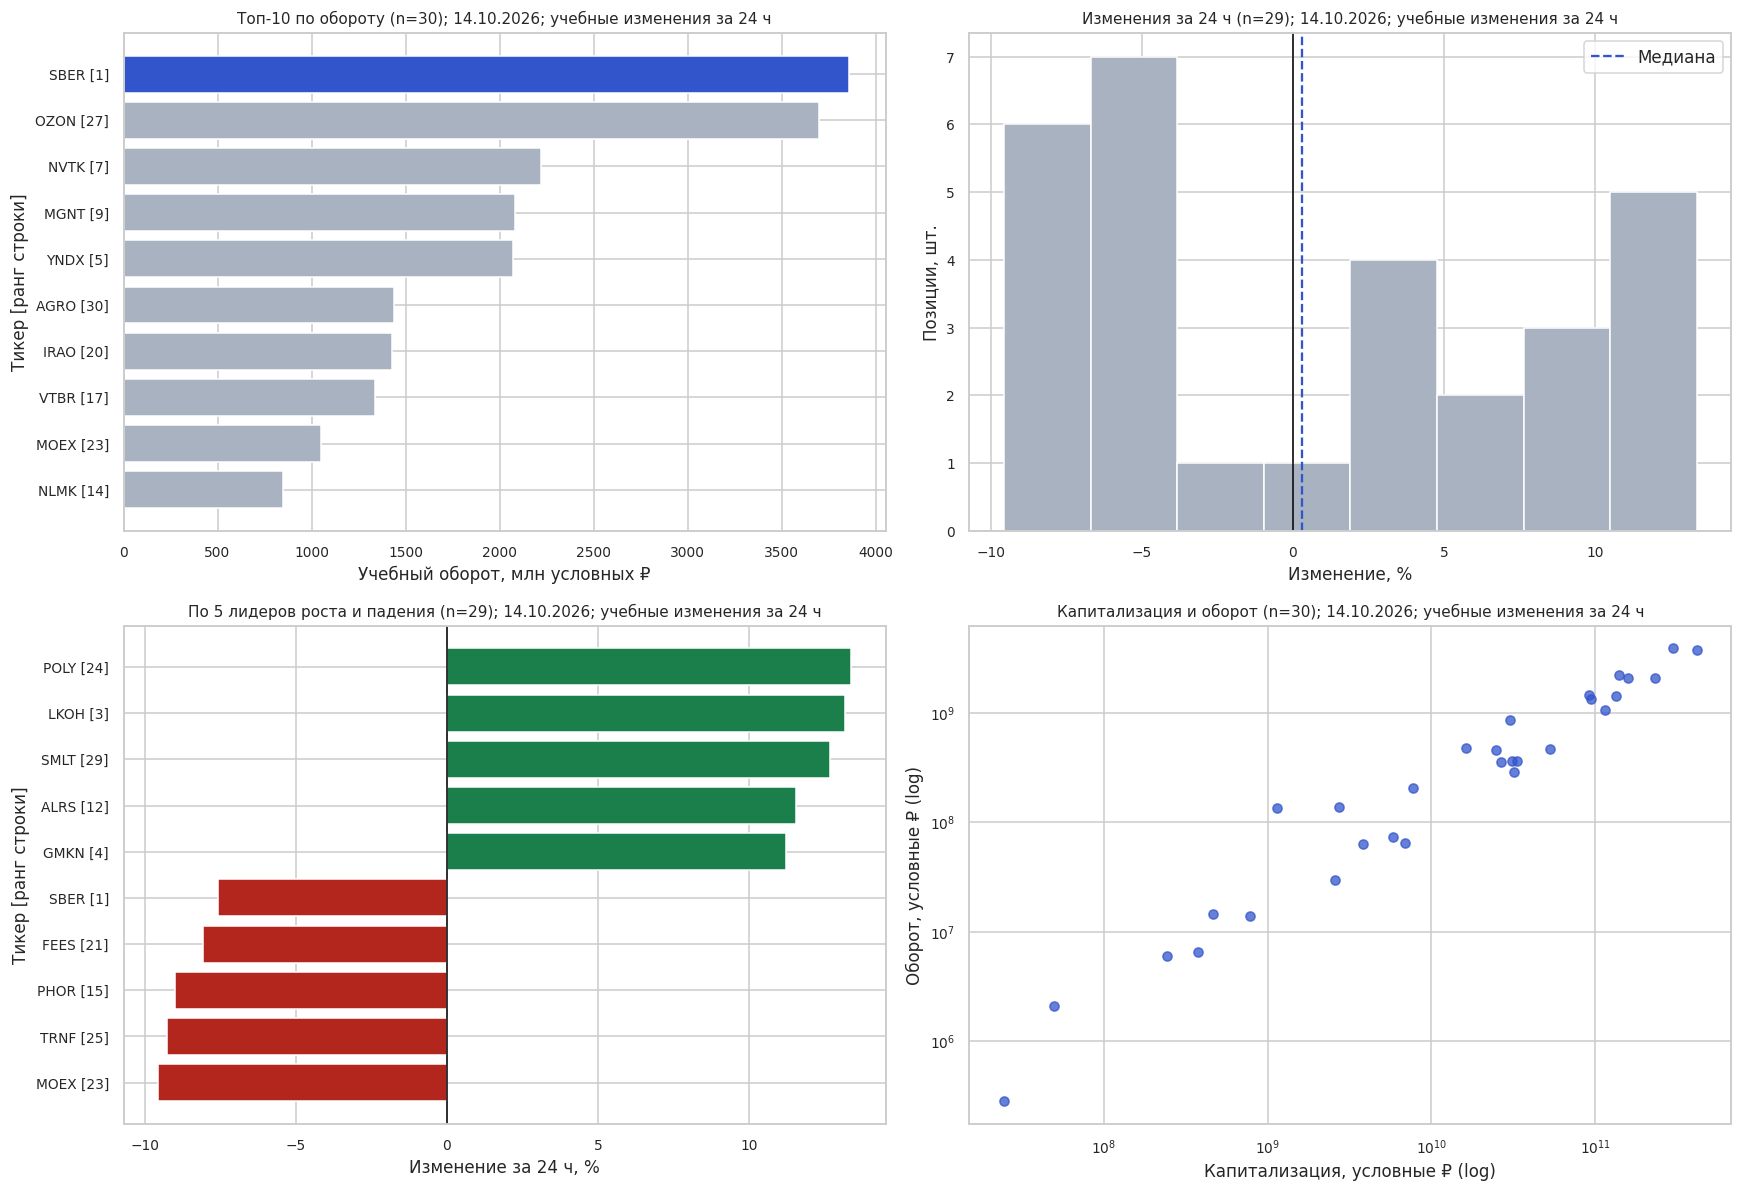

,row_id,ticker,volume_value,mcap_value,turnover_ratio,change_24h
18,v17-19,SNGS,473900000.0,1.615000e+10,0.029344,0.0316
1,v17-2,GAZP,206500000.0,7.730000e+09,0.026714,-0.0643
24,v17-25,TRNF,138000000.0,2.730000e+09,0.050549,-0.0926
12,v17-13,CHMF,135300000.0,1.140000e+09,0.118684,0.0758
23,v17-24,POLY,14600000.0,4.626000e+08,0.031561,0.1337
9,v17-10,MTSS,6000000.0,2.440000e+08,0.024590,-0.0521
2,v17-3,LKOH,2100000.0,4.960000e+07,0.042339,0.1316


### Отчёт для ЛПР — вариант 17

**Источник и качество.** Собраны все 30 строки локального учебного стенда stocks; дата среза 14.10.2026; учебные изменения за 24 ч. Сбор выполнен Playwright, строки разобраны lxml/XPath. Цена и изменение заполнены в 96.7% и 96.7% строк; оборот и капитализация — в 100%. Пропуски не заменены нулями.

**Наблюдения.** Лидер по обороту — SBER [1]: 3.86 млрд условных ₽. Три позиции дают 41.5% общего оборота. Медианное изменение за 24 ч — +0.31%; рост показали 15 из 29 строк с известным изменением. Ранговая корреляция капитализации с оборотом — 0.962; высокая связь в этом примере частично заложена генератором данных и не доказывает рыночную закономерность.

**Решения для демонстрационного watchlist.** 1. Сначала проверить 7 позиций с отношением оборота к капитализации не ниже 2.30% и заполненными ценой/изменением. Ожидаемый эффект — сокращение списка ручной проверки; проверить покрытие оборота и время анализа относительно просмотра всех 30 строк. 2. Отдельно проверить по 5 лидеров роста и падения: ожидаемый эффект — выявление необычных движений; подтвердить движение историей котировок и вторым источником, а не одним срезом. 3. Ввести ежедневный контроль пропусков и концентрации (сейчас топ-3: 41.5%); проверять долю заполненных полей и устойчивость состава списка за 20 торговых дней.

**Ограничения.** Числа синтетические, это не рекомендации покупать акции. Профиль stocks содержит демонстрационные российские тикеры и разные сектора, а не фактическую выборку азиатских IT-компаний. Тикеры повторяются, поэтому строки идентифицированы рангом и вариантом. Валюта цены — RUB; единицы оборота/капитализации условны. Источник округляет K/M/B; один суточный срез не даёт волатильность или прогноз. Для применения варианта 17 нужен лицензированный источник, фильтр Asia + Technology, уникальные идентификаторы, единая валюта и проверка, выражен ли volume в акциях или деньгах. Для реальных торгов turnover/mcap допустим только после согласования единиц.


In [18]:
#@title Шаг 7. EDA и рекомендации для watchlist
from datetime import timezone, timedelta
from IPython.display import Markdown, Image, display
PLOTS_DONE = False
if df.empty:
    print("Анализ пропущен: выборка пуста; проверьте XPath", CFG["row_xpath"])
else:
    snapshot_at = datetime.now(timezone(timedelta(hours=3)))
    period = snapshot_at.strftime("%d.%m.%Y") + "; учебные изменения за 24 ч"
    df["label"] = df.ticker + " [" + df["rank"].astype(str) + "]"
    # Шаблон стенда задаёт синтетический оборот и капитализацию.
    top = df.nlargest(10, "volume_value").sort_values("volume_value")
    changes = df.change_24h.dropna()
    cohorts = pd.concat([df.nsmallest(5, "change_24h"), df.nlargest(5, "change_24h")]).sort_values("change_24h")
    pair = df[(df.mcap_value > 0) & (df.volume_value > 0)]
    fig, ax = plt.subplots(2, 2, figsize=(16, 11))
    colors = ["#A8B2C1"] * len(top)
    colors[-1] = "#3355CC"
    ax[0, 0].barh(top.label, top.volume_value / 1e6, color=colors)
    ax[0, 0].set(title=f"Топ-10 по обороту (n={len(df)}); {period}", xlabel="Учебный оборот, млн условных ₽", ylabel="Тикер [ранг строки]")
    ax[0, 1].hist(changes * 100, bins=8, color="#A8B2C1", edgecolor="white")
    ax[0, 1].axvline(0, color="black", linewidth=1)
    ax[0, 1].axvline(changes.median() * 100, color="#3355CC", linestyle="--", label="Медиана")
    ax[0, 1].set(title=f"Изменения за 24 ч (n={len(changes)}); {period}", xlabel="Изменение, %", ylabel="Позиции, шт.")
    ax[0, 1].legend()
    ax[1, 0].barh(cohorts.label, cohorts.change_24h * 100, color=["#B3261E" if v < 0 else "#1A7F4B" for v in cohorts.change_24h])
    ax[1, 0].axvline(0, color="black", linewidth=1)
    ax[1, 0].set(title=f"По 5 лидеров роста и падения (n={len(changes)}); {period}", xlabel="Изменение за 24 ч, %", ylabel="Тикер [ранг строки]")
    ax[1, 1].scatter(pair.mcap_value, pair.volume_value, c="#3355CC", alpha=.75)
    ax[1, 1].set_xscale("log")
    ax[1, 1].set_yscale("log")
    ax[1, 1].set(title=f"Капитализация и оборот (n={len(pair)}); {period}", xlabel="Капитализация, условные ₽ (log)", ylabel="Оборот, условные ₽ (log)")
    for axis in ax.flat:
        axis.title.set_fontsize(10)
        axis.tick_params(labelsize=9)
    fig.tight_layout()
    fig.savefig(WORK_DIR / "analysis.png", dpi=150, bbox_inches="tight")
    plt.show()
    PLOTS_DONE = True
    total_volume = df.volume_value.sum()
    concentration = df.nlargest(3, "volume_value").volume_value.sum() / total_volume
    leader = df.loc[df.volume_value.idxmax()]
    corr = pair[["mcap_value", "volume_value"]].corr(method="spearman").iloc[0, 1]
    ratio = df.volume_value / df.mcap_value.replace(0, np.nan)
    df["turnover_ratio"] = ratio
    cutoff = ratio.quantile(.75)
    watchlist = df[(ratio >= cutoff) & df.price_value.notna() & df.change_24h.notna()].sort_values("volume_value", ascending=False)
    display(watchlist[["row_id", "ticker", "volume_value", "mcap_value", "turnover_ratio", "change_24h"]])
    report = f"""### Отчёт для ЛПР — вариант 17

**Источник и качество.** Собраны все {len(df)} строки локального учебного стенда stocks; дата среза {period}. Сбор выполнен Playwright, строки разобраны lxml/XPath. Цена и изменение заполнены в {df.price_value.notna().mean():.1%} и {df.change_24h.notna().mean():.1%} строк; оборот и капитализация — в 100%. Пропуски не заменены нулями.

**Наблюдения.** Лидер по обороту — {leader["label"]}: {leader.volume_value / 1e9:.2f} млрд условных ₽. Три позиции дают {concentration:.1%} общего оборота. Медианное изменение за 24 ч — {changes.median():+.2%}; рост показали {int((changes > 0).sum())} из {len(changes)} строк с известным изменением. Ранговая корреляция капитализации с оборотом — {corr:.3f}; высокая связь в этом примере частично заложена генератором данных и не доказывает рыночную закономерность.

**Решения для демонстрационного watchlist.** 1. Сначала проверить {len(watchlist)} позиций с отношением оборота к капитализации не ниже {cutoff:.2%} и заполненными ценой/изменением. Ожидаемый эффект — сокращение списка ручной проверки; проверить покрытие оборота и время анализа относительно просмотра всех 30 строк. 2. Отдельно проверить по 5 лидеров роста и падения: ожидаемый эффект — выявление необычных движений; подтвердить движение историей котировок и вторым источником, а не одним срезом. 3. Ввести ежедневный контроль пропусков и концентрации (сейчас топ-3: {concentration:.1%}); проверять долю заполненных полей и устойчивость состава списка за 20 торговых дней.

**Ограничения.** Числа синтетические, это не рекомендации покупать акции. Профиль stocks содержит демонстрационные российские тикеры и разные сектора, а не фактическую выборку азиатских IT-компаний. Тикеры повторяются, поэтому строки идентифицированы рангом и вариантом. Валюта цены — RUB; единицы оборота/капитализации условны. Источник округляет K/M/B; один суточный срез не даёт волатильность или прогноз. Для применения варианта 17 нужен лицензированный источник, фильтр Asia + Technology, уникальные идентификаторы, единая валюта и проверка, выражен ли volume в акциях или деньгах. Для реальных торгов turnover/mcap допустим только после согласования единиц.
"""
    display(Markdown(report))
    (WORK_DIR / "report.md").write_text(report, encoding="utf-8")

**Интерпретация.** На первом графике важна не высота столбцов, а концентрация: если на три позиции приходится больше половины оборота, рынок узкий, и ликвидность остальных позиций иллюзорна. На распределении смотрите на медиану и симметрию: длинный хвост влево — отдельные обвалы, а не общий спад. Когорты дают список для ручной проверки: экстремальные движения часто оказываются артефактом (низкая база, разовая сделка). Диаграмма «капитализация — оборот» в логарифмических шкалах выявляет крупные, но неликвидные позиции: именно они создают риск исполнения. Текстовый отчёт — шаблон, который вы адаптируете под свой вариант.

## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель; параметры подставляются в код автоматически по значению `VARIANT`. Столбец «Профиль стенда» задаёт набор данных учебной витрины — это обязательная часть работы. Столбцы «Реальная площадка» и «Легальный источник» относятся к исследовательской части: изучить ограничения площадки, найти XHR-эндпоинт с данными и указать законный способ получить те же данные.

| № | Доменная область | Профиль стенда | Реальная площадка (разбор ограничений) | Легальный источник тех же данных | Аналитическая задача и решение |
|---:|---|---|---|---|---|
| 1 | Криптовалютный арбитраж | `crypto` | CoinMarketCap — раздел Cryptocurrencies | CoinGecko API (/coins/markets) | Топ-10 по обороту, разброс суточного изменения; решение: где держать лимиты маркет-мейкера |
| 2 | Фондовые индексы АТР | `stocks` | Investing.com — Asia/Pacific indices | MOEX ISS API, Alpha Vantage | Сравнение доходностей, когорты роста и падения; решение: ребалансировка регионального портфеля |
| 3 | Мониторинг цен на технологические металлы | `metals` | Trading Economics — Commodities | World Bank Commodity Price Data (Pink Sheet) | Топ по обороту и волатильности; решение: сроки хеджирования закупок |
| 4 | Ценовая разведка маркетплейса: смартфоны | `ecom` | Агрегатор цен категории «Смартфоны» | Открытые фиды поставщиков, API маркетплейса продавца | Ценовые сегменты и доля дефицита; решение: цена входа в категорию |
| 5 | Трекинг раундов венчурных сделок | `startups` | Crunchbase — Funding Rounds | OpenAlex, Dealroom API (по подписке), данные ЕГРЮЛ | Распределение размеров раундов, топ-инвесторы; решение: фокус отраслевого фонда |
| 6 | Ликвидность DeFi-протоколов | `crypto` | DeFiLlama — TVL rankings | DefiLlama API (открытый) | TVL и оборот в логарифмических шкалах; решение: лимиты на протокол |
| 7 | Голубые фишки российского рынка | `stocks` | Investing.com — Russian stocks | MOEX ISS API (iss.moex.com) | Топ по обороту, медиана изменения; решение: состав торговой корзины дня |
| 8 | Драгоценные металлы и хеджирование | `metals` | Kitco — Live spot prices | LBMA открытые котировки, ЦБ РФ учётные цены | Динамика и разброс; решение: доля металлов в резерве |
| 9 | Мониторинг цен на ноутбуки | `ecom` | Витрина категории «Ноутбуки» | API прайс-агрегатора продавца | Медианы по сегментам, ценовые кластеры; решение: позиционирование новой линейки |
| 10 | Скоринг стартап-экосистемы региона | `startups` | Dealroom — региональные дашборды | OpenAlex, Росстат, ЕГРЮЛ | Когорты по темпу роста; решение: приоритеты акселератора |
| 11 | Стейблкоины и риск депега | `crypto` | CoinMarketCap — Stablecoins | CoinGecko API | Отклонение от номинала, объёмы; решение: лимиты казначейства |
| 12 | Европейские индексы и открытие торгов | `stocks` | Investing.com — European indices | Alpha Vantage, Stooq | Утренние гэпы, распределение; решение: тайминг заявок |
| 13 | Аккумуляторные металлы и цепочка поставок | `metals` | SMM — Battery metals | USGS Mineral Commodity Summaries | Волатильность лития и кобальта; решение: пересмотр закупочных контрактов |
| 14 | Бытовая техника: акции конкурентов | `ecom` | Витрина категории «Бытовая техника» | Фиды партнёрских программ | Глубина скидок, доля позиций в наличии; решение: календарь промо |
| 15 | FinTech-стартапы: динамика найма | `startups` | AngelList / Wellfound — Jobs | «Работа в России» (opendata.trudvsem.ru) | Число вакансий против оценки; решение: выбор объекта для partnership |
| 16 | NFT и игровые токены | `crypto` | CoinGecko — Gaming category | CoinGecko API | Топ по обороту, хвосты распределения; решение: отсев неликвида |
| 17 | Азиатские IT-эмитенты | `stocks` | Yahoo Finance — Screener | Alpha Vantage, Nasdaq Data Link | Капитализация против оборота; решение: включение в watchlist |
| 18 | Редкоземельные элементы и импортозависимость | `metals` | Trading Economics — Rare earth | USGS, World Bank | Топ по цене и изменение; решение: стратегический запас |
| 19 | Аудиотехника: ассортиментная матрица | `ecom` | Витрина категории «Аудио» | API маркетплейса продавца | Медиана цены по секторам; решение: сокращение хвоста SKU |
| 20 | HealthTech: инвестиционная активность | `startups` | Crunchbase — HealthTech | OpenAlex, ClinicalTrials.gov API | Размер раунда и стадия; решение: вход в нишу |
| 21 | Кросс-биржевой спред по BTC | `crypto` | CoinMarketCap — Markets | Binance и Bybit публичные API | Спреды и обороты по площадкам; решение: маршрутизация ордеров |
| 22 | Дивидендные истории рынка РФ | `stocks` | Smart-lab — Дивиденды | MOEX ISS API | Доходность против капитализации; решение: дивидендный портфель |
| 23 | Промышленные металлы и энергопереход | `metals` | LME — Metals prices | World Bank Pink Sheet, ЦБ РФ | Когорты роста и падения; решение: индексация контрактов |
| 24 | Маркетплейс: мониторинг дефицита | `ecom` | Витрина «Все товары» | API продавца, фиды поставщиков | Доля отсутствующих позиций; решение: перераспределение закупки |
| 25 | EdTech: выручка и раунды | `startups` | HolonIQ — EdTech dashboards | OpenAlex, открытые отчёты фондов | Топ по оценке; решение: сделки M&A |
| 26 | Крипто-инфраструктура: L2-решения | `crypto` | L2BEAT — Scaling | L2BEAT API, DefiLlama API | TVL и рост; решение: выбор сети для интеграции |
| 27 | Американские техгиганты | `stocks` | Yahoo Finance — Most active | Alpha Vantage, Finnhub | Оборот и изменение; решение: наблюдение за концентрацией |
| 28 | Строительные материалы: индекс цен | `metals` | Trading Economics — Steel | Росстат, World Bank | Медианы и разброс; решение: бюджет строительного проекта |
| 29 | Недвижимость: мониторинг предложений | `ecom` | Агрегатор объявлений недвижимости | Открытые данные Росреестра, ЕМИСС | Распределение цен, когорты; решение: цена входа на локальный рынок |
| 30 | Комплексный мониторинг рыночной витрины (эталон) | `crypto` | CoinMarketCap — Cryptocurrencies | CoinGecko API (/coins/markets) | Топ-10 по обороту с выделением лидера, распределение изменения за 24 ч, когорты роста и падения, капитализация против оборота; решение: где концентрировать лимиты и что проверить до прогноза |

Минимум для зачёта по сбору: **все 30 позиций витрины** (то есть отработавшая догрузка), не менее 90 % распознанных числовых значений и четыре графика из столбца «Аналитическая задача».

## Критерии оценивания

### Балльная структура (10 баллов)

| Блок | Что проверяется | Максимум |
|---|---|---:|
| 1. Окружение и запуск браузера | Корректная установка, флаги `--no-sandbox` и `--disable-dev-shm-usage`, реалистичный контекст, блокировка лишних ресурсов | 1,0 |
| 2. Обход препятствий | Закрытие cookie-баннера и модальных окон каскадом селекторов; работа при отсутствии баннера | 1,0 |
| 3. Ожидания | Явные ожидания вместо `time.sleep`; ожидание по числу строк при догрузке; корректный таймаут | 1,5 |
| 4. XPath и сбор | Устойчивые селекторы (`data-testid`, `contains`, оси), полнота выборки, разделение «браузер → HTML → lxml» | 2,0 |
| 5. Очистка и Excel | Суффиксы K/M/B, проценты долями, валюта, даты, пропуски как `NaN`; тесты функций; оформленная выгрузка | 2,0 |
| 6. Аналитика и графики | Четыре графика по варианту, корректные метрики, оформление | 1,5 |
| 7. Бизнес-вывод | Решения, а не наблюдения; числа из собственного запуска; названы ограничения | 1,0 |

### Шкала

| Баллы | Оценка | Содержательный смысл |
|---|---|---|
| 9–10 | **A** (отлично) | Скрипт устойчив, селекторы надёжны, очистка полная, выводы управленческие |
| 8–9 | **B** (хорошо) | Данные собраны и очищены, есть шероховатости в обработке ошибок или оформлении |
| 7–8 | **C** (удовлетворительно) | Сбор работает только «на удачном прогоне», ожидания частично на паузах |
| 6–7 | **D** (зачтено с замечаниями) | Данные собраны неполно либо очистка теряет часть значений |
| < 6 | **F** (не зачтено) | Скрипт не воспроизводится, данные собраны вручную или подменены |

### Требования к отказоустойчивости

Скрипт обязан переживать без падения ноутбука:

1. **Таймаут ожидания** (`TimeoutError` / `TimeoutException`) — перехват, сохранение скриншота и HTML, понятное сообщение о вероятной причине.
2. **Пустую выборку** — проверка `len(rows) == 0` до перехода к анализу, с указанием, какой селектор не сработал.
3. **Отсутствие оверлея** — отсутствие баннера не должно приводить к исключению.
4. **Частично заполненную строку** — отсутствующая ячейка даёт `None`, а не обрывает цикл.
5. **Нераспознанное значение** — `n/a`, `—`, пустая строка превращаются в `NaN`, но строка остаётся в выборке.
6. **Ограничение цикла догрузки** — максимальное число кликов и условие выхода при отсутствии роста.

### Требования к оформлению графиков

* заголовок с указанием объёма выборки (`n = …`) и периода;
* подписи обеих осей с единицами измерения (млн ₽, %, шт.);
* шрифт не мельче 9 пт, отсутствие наложения подписей;
* единая палитра: один акцентный цвет для выделяемой категории, нейтральный — для остальных; зелёный и красный только по смыслу «рост/падение»;
* опорные линии (ноль, медиана, порог) там, где они помогают читать график;
* логарифмическая шкала, если значения различаются на порядки, с явной пометкой в подписи оси;
* никаких «радужных» палитр на категориальных данных и трёхмерных эффектов.

### Штрафы

| Нарушение | Штраф |
|---|---:|
| `time.sleep()` вместо явных ожиданий в сценарии сбора | −1,0 |
| Данные получены вручную (скопированы), а не собраны скриптом | −4,0 |
| Попытка обхода капчи, Cloudflare или сбор за логином | работа не принимается |
| Сбор персональных данных | работа не принимается |
| Нет обработки исключений при сборе | −1,0 |
| Проценты сохранены как 2.5 вместо 0.025 или пропуски заменены нулями | −1,0 |
| Графики без подписей осей и единиц измерения | −0,5 |
| Ноутбук сдан без выводов ячеек | −1,0 |

In [19]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []
def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Вариант выбран корректно", 1 <= VARIANT <= 30)
check("Браузер стартовал и страница открылась", bool(html) and len(html) > 1000)
check("Cookie-баннер обработан (или его не было)", "cookie-banner" not in html or USE_LIVE_TARGET,
      "баннер остался в DOM — клик не сработал")
check("Собраны все строки витрины (≥ 30)", len(raw_df) >= 30,
      "не отработала догрузка по кнопке «Показать ещё»")
check("Числовые поля распознаны не хуже 90 %",
      df["volume_value"].notna().mean() >= 0.9 and df["mcap_value"].notna().mean() >= 0.9)
check("Проценты приведены к долям единицы",
      df["change_24h"].dropna().abs().max() < 1.5 if df["change_24h"].notna().any() else False,
      "значение вроде 2.5 вместо 0.025 — забыли поделить на 100")
check("Пропуски не превратились в нули",
      df["price_value"].isna().sum() > 0 or df["change_24h"].isna().sum() > 0,
      "на стенде есть 'n/a' и '—': они должны остаться пропусками")
check("Файл Excel выгружен", EXCEL_PATH.exists() and EXCEL_PATH.stat().st_size > 4000)
check("Скриншот страницы сохранён как доказательство сбора", (WORK_DIR / "page.png").exists())
check("Явные ожидания вместо пауз", "time.sleep" not in globals().get("COLLECT_SOURCE", "time.sleep"),
      "уберите time.sleep из сценария сбора")
check("Построены графики", len(plt.get_fignums()) > 0 or globals().get("PLOTS_DONE", False),
      "выполните шаг 7 до самопроверки")

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))

Выполнено: 11 из 11

  ✅ Вариант выбран корректно
  ✅ Браузер стартовал и страница открылась
  ✅ Cookie-баннер обработан (или его не было)
  ✅ Собраны все строки витрины (≥ 30)
  ✅ Числовые поля распознаны не хуже 90 %
  ✅ Проценты приведены к долям единицы
  ✅ Пропуски не превратились в нули
  ✅ Файл Excel выгружен
  ✅ Скриншот страницы сохранён как доказательство сбора
  ✅ Явные ожидания вместо пауз
  ✅ Построены графики


## Задание со звёздочкой (до +2 балла)

Разовый сбор — учебная задача; производственная задача — устойчивый мониторинг. Выберите одно направление и доведите до измеримого результата.

In [20]:
#@title Задание D. Устойчивость селекторов и исследование Yahoo Finance
# Каскад: testid → семантические атрибуты → заголовки таблицы.
def parse_resilient(content, cfg):
    if not content:
        return []
    tree = lxml_html.fromstring(content)
    nodes = tree.xpath(cfg["row_xpath"])
    if not nodes:
        nodes = tree.xpath("//tr[@data-rank]")
    if not nodes:
        tables = tree.xpath("//table[.//th[normalize-space(.)='Тикер']]")
        nodes = tables[0].xpath(".//tbody/tr[td]") if tables else []
    result = []
    for node in nodes:
        row = {}
        for field in cfg["fields"]:
            values = node.xpath(".//td[@data-testid='" + field + "']")
            if not values:
                # Позиционный резерв только при известном заголовке колонки.
                labels = {"rank": "#", "ticker": "Тикер", "name": "Название", "sector": "Сектор", "price": "Цена", "change": "24ч", "volume": "Объём", "mcap": "Капитализация", "listed": "Листинг"}
                table = node.xpath("ancestor::table[1]")[0]
                headers = table.xpath(".//thead/tr[1]/th")
                positions = [i for i, h in enumerate(headers) if h.xpath("normalize-space(.)") == labels[field]]
                cells = node.xpath("./td")
                values = [cells[positions[0]]] if positions and positions[0] < len(cells) else []
            row[field] = values[0].xpath("normalize-space(.)") if values else None
        result.append(row)
    return result

mutations = [("оригинал", html),
             ("удалены testid", re.sub(r' data-testid="[^"\n]*"', "", html)),
             ("переименованы классы", re.sub(r' class="[^"\n]*"', ' class="changed"', html)),
             ("нет testid и ранга", re.sub(r' data-(?:testid|rank)="[^"\n]*"', "", html))]
for name, changed in mutations:
    got = parse_resilient(changed, CFG)
    assert got == records, name
    print("✅", name, "— сохранены все", len(got), "строк и поля")
assert parse_resilient("", CFG) == []
partial = html.replace('<td class="t" data-testid="ticker">SBER</td>', "", 1)
assert len(parse_resilient(partial, CFG)) == len(records)
# Проверка штатного отсутствия баннера и конечного ожидания.
async def test_waits():
    async with async_playwright() as pw:
        browser, context = await new_context(pw, HEADLESS)
        try:
            page = await context.new_page()
            await page.set_content("<html><body>Нет баннера и таблицы</body></html>")
            assert await dismiss_overlays(page) == []
            try:
                await wait_for_rows(page, CFG["row_xpath"], timeout=200)
            except PWTimeout:
                print("✅ Нет баннера: без ошибки. Нет строк: контролируемый таймаут.")
            else:
                raise AssertionError("Ожидался таймаут")
        finally:
            await browser.close()
await test_waits()
print("Тесты устойчивости завершены")

# Исследование публичных правил и сети; котировки с Yahoo не собираются.
import requests
from urllib.parse import urlsplit
from urllib.robotparser import RobotFileParser
research = []
for name, url in [("robots", "https://finance.yahoo.com/robots.txt"), ("terms", "https://legal.yahoo.com/us/en/yahoo/terms/otos/index.html")]:
    try:
        r = requests.get(url, headers={"User-Agent": UA}, timeout=15)
        research.append({"документ": name, "URL": url, "HTTP": r.status_code})
        (WORK_DIR / ("yahoo_" + name + ".txt")).write_text(r.text, encoding="utf-8")
        if name == "robots" and r.status_code == 200:
            robot = RobotFileParser()
            robot.parse(r.text.splitlines())
            print("robots: can_fetch для screener:", robot.can_fetch(UA, CFG["live_url"]))
        if name == "terms" and r.status_code == 200:
            text = lxml_html.fromstring(r.text).text_content()
            print("В тексте условий есть automated:", "automated" in text.lower())
    except requests.RequestException as exc:
        research.append({"документ": name, "URL": url, "HTTP": type(exc).__name__})
display(pd.DataFrame(research))

async def inspect_public_network():
    seen = []
    async with async_playwright() as pw:
        browser, context = await new_context(pw, HEADLESS)
        try:
            page = await context.new_page()
            def record_response(response):
                if response.request.resource_type in {"xhr", "fetch"}:
                    u = urlsplit(response.url)
                    if "yahoo" in u.netloc and any(x in u.path for x in ["finance", "screener", "quote"]):
                        seen.append({"host": u.netloc, "path": u.path, "HTTP": response.status})
            page.on("response", record_response)
            response = await page.goto(CFG["live_url"], wait_until="load", timeout=15000)
            print("Публичная страница Yahoo, HTTP:", response.status if response else None)
            await page.screenshot(path=str(WORK_DIR / "yahoo_research.png"), full_page=True)
        except (PWTimeout, PWError) as exc:
            print("Сеть Yahoo недоступна для исследования:", type(exc).__name__)
        finally:
            await browser.close()
    return list({(r["host"], r["path"], r["HTTP"]): r for r in seen}.values())
yahoo_xhr = await inspect_public_network()
display(pd.DataFrame(yahoo_xhr))
print("При недоступности или запрете live-сбор не включается; USE_LIVE_TARGET =", USE_LIVE_TARGET)
print("Легальный источник: Alpha Vantage — https://www.alphavantage.co/documentation/ ; Nasdaq Data Link — https://docs.data.nasdaq.com/")
print("Для цен/объёма: TIME_SERIES_DAILY или GLOBAL_QUOTE; для капитализации: OVERVIEW. Нужен собственный ключ и проверка покрытия бирж/лицензии. Объём в акциях не равен денежному обороту.")

✅ оригинал — сохранены все 30 строк и поля
✅ удалены testid — сохранены все 30 строк и поля
✅ переименованы классы — сохранены все 30 строк и поля
✅ нет testid и ранга — сохранены все 30 строк и поля
✅ Нет баннера: без ошибки. Нет строк: контролируемый таймаут.
Тесты устойчивости завершены
robots: can_fetch для screener: True
В тексте условий есть automated: True


,документ,URL,HTTP
0,robots,https://finance.yahoo.com/robots.txt,200
1,terms,https://legal.yahoo.com/us/en/yahoo/terms/otos...,200


Публичная страница Yahoo, HTTP: 200


,host,path,HTTP
0,query1.finance.yahoo.com,/v7/finance/quote,200


При недоступности или запрете live-сбор не включается; USE_LIVE_TARGET = False
Легальный источник: Alpha Vantage — https://www.alphavantage.co/documentation/ ; Nasdaq Data Link — https://docs.data.nasdaq.com/
Для цен/объёма: TIME_SERIES_DAILY или GLOBAL_QUOTE; для капитализации: OVERVIEW. Нужен собственный ключ и проверка покрытия бирж/лицензии. Объём в акциях не равен денежному обороту.


## Исследовательская часть — Yahoo Finance

Дата проверки: 14.10.2026. robots.txt и Terms of Service получены с HTTP 200. Для пути Screener robots.can_fetch вернул True, однако это не разрешение на сбор/перепубликацию. В проверенной редакции условий Yahoo автоматический доступ и сбор данных требуют предварительного явного разрешения. Поэтому USE_LIVE_TARGET=False, регулярный сбор Yahoo не запускается. Ссылки: https://finance.yahoo.com/robots.txt ; https://legal.yahoo.com/us/en/yahoo/terms/otos/index.html .

При диагностическом открытии публичной страницы реально наблюдался XHR/fetch https://query1.finance.yahoo.com/v7/finance/quote со статусом HTTP 200. Это внутренний канал сайта, а не предоставленная пользователю лицензия/API-контракт. Пути ответов приведены в предыдущей ячейке; параметры запроса и служебные данные не публикуются. Котировки Yahoo не включены в учебный датасет.

Лицензированный путь: Alpha Vantage (https://www.alphavantage.co/documentation/), TIME_SERIES_DAILY/GLOBAL_QUOTE для цен и объёма, OVERVIEW для капитализации. Nasdaq Data Link: https://docs.data.nasdaq.com/ — доступ и покрытие зависят от набора. Нужны собственный ключ, проверка покрытия азиатских бирж и условий использования/публикации. Volume в акциях не равен денежному обороту; нельзя напрямую делить его на капитализацию в валюте.

Для применения к бизнес-задаче варианта 17 нужно отфильтровать Asia + Technology, сопоставить биржи, валюты и даты торгов. В обязательной части используется воспроизводимый локальный стенд stocks с синтетическими значениями, а не реальный рынок.


Самопроверка: 11 из 11


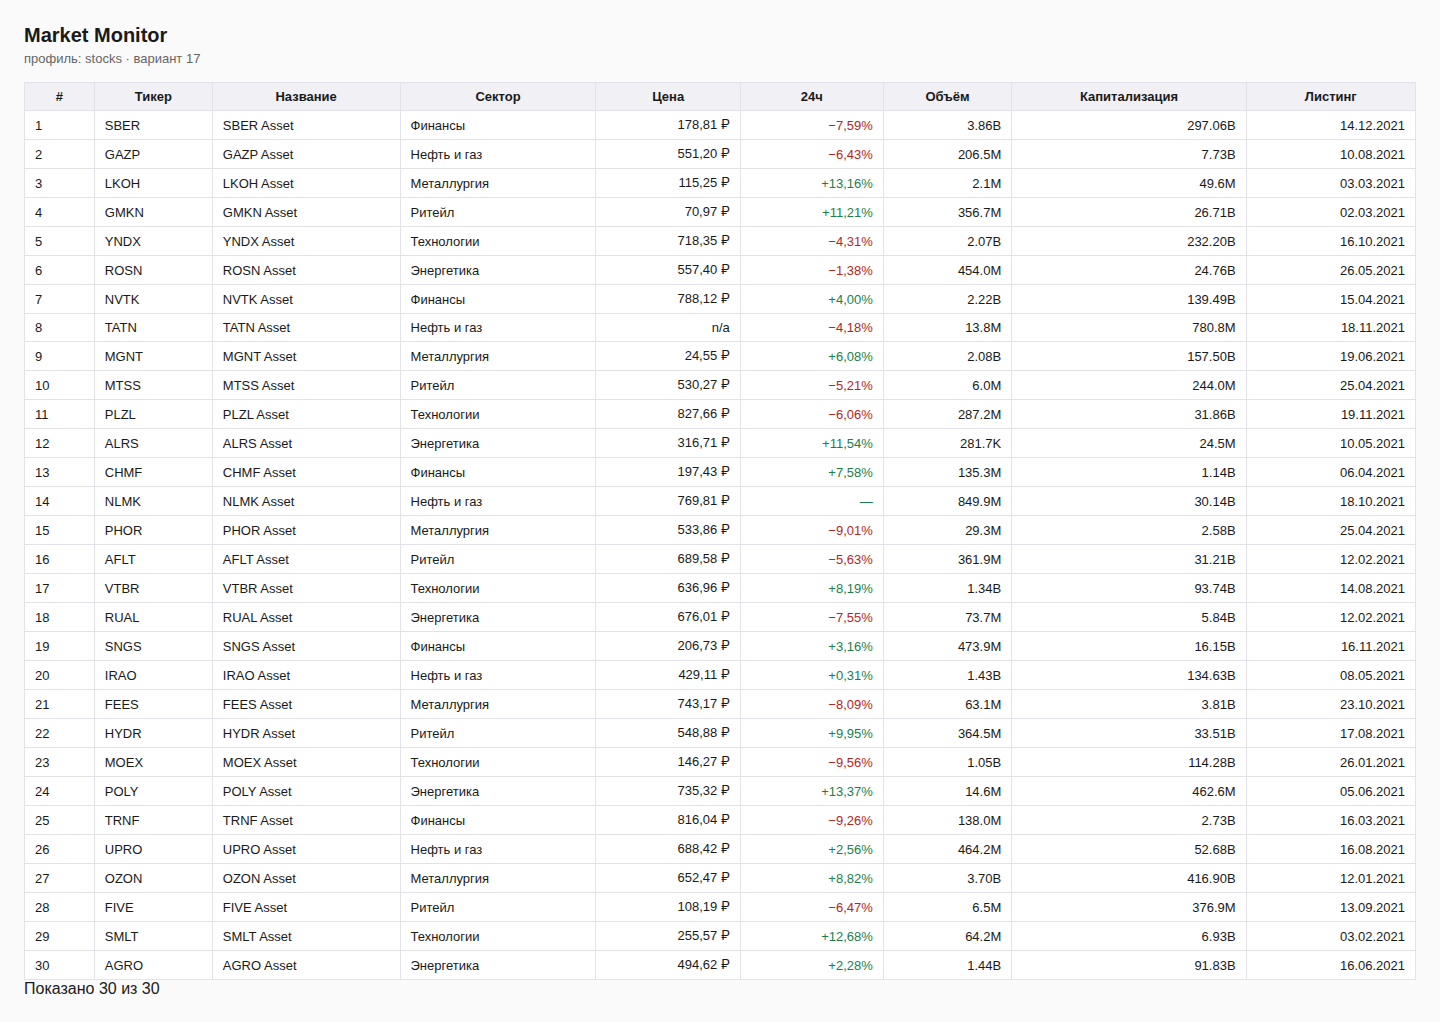

Результаты: /content/lr1/lr1_variant_17_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
#@title Исследовательское заключение и пакет результатов
research_note = """## Исследовательская часть — Yahoo Finance

Дата проверки: 14.10.2026. robots.txt и Terms of Service получены с HTTP 200. Для пути Screener robots.can_fetch вернул True, однако это не разрешение на сбор/перепубликацию. В проверенной редакции условий Yahoo автоматический доступ и сбор данных требуют предварительного явного разрешения. Поэтому USE_LIVE_TARGET=False, регулярный сбор Yahoo не запускается. Ссылки: https://finance.yahoo.com/robots.txt ; https://legal.yahoo.com/us/en/yahoo/terms/otos/index.html .

При диагностическом открытии публичной страницы реально наблюдался XHR/fetch https://query1.finance.yahoo.com/v7/finance/quote со статусом HTTP 200. Это внутренний канал сайта, а не предоставленная пользователю лицензия/API-контракт. Пути ответов приведены в предыдущей ячейке; параметры запроса и служебные данные не публикуются. Котировки Yahoo не включены в учебный датасет.

Лицензированный путь: Alpha Vantage (https://www.alphavantage.co/documentation/), TIME_SERIES_DAILY/GLOBAL_QUOTE для цен и объёма, OVERVIEW для капитализации. Nasdaq Data Link: https://docs.data.nasdaq.com/ — доступ и покрытие зависят от набора. Нужны собственный ключ, проверка покрытия азиатских бирж и условий использования/публикации. Volume в акциях не равен денежному обороту; нельзя напрямую делить его на капитализацию в валюте.

Для применения к бизнес-задаче варианта 17 нужно отфильтровать Asia + Technology, сопоставить биржи, валюты и даты торгов. В обязательной части используется воспроизводимый локальный стенд stocks с синтетическими значениями, а не реальный рынок.
"""
(WORK_DIR / "research.md").write_text(research_note, encoding="utf-8")
display(Markdown(research_note))
print("Самопроверка:", sum(passed for _, passed, _ in checks), "из", len(checks))
display(Image(filename=str(WORK_DIR / "page.png"), width=1000))
import zipfile
BUNDLE_PATH = WORK_DIR / "lr1_variant_17_results.zip"
with zipfile.ZipFile(BUNDLE_PATH, "w", zipfile.ZIP_DEFLATED) as archive:
    for name in ["lr1_variant_17.xlsx", "page.png", "page.html", "analysis.png", "data.csv", "report.md", "research.md", "yahoo_robots.txt", "yahoo_terms.txt", "yahoo_research.png"]:
        path = WORK_DIR / name
        if path.exists():
            archive.write(path, arcname=name)
print("Результаты:", BUNDLE_PATH)
from google.colab import files
files.download(str(BUNDLE_PATH))

In [22]:
#@title Финальное оформление и проверка Excel
# После визуальной проверки расширяем числовые колонки и унифицируем формат дат.
book = load_workbook(EXCEL_PATH)
for ws in book.worksheets:
    for cells in ws.columns:
        header = cells[0].value
        col = cells[0].column_letter
        if header in ["volume_value", "mcap_value", "total_volume", "total_mcap"]:
            ws.column_dimensions[col].width = 24
        elif header in ["change_24h", "median_change"]:
            ws.column_dimensions[col].width = 22
        elif header == "listed_date":
            ws.column_dimensions[col].width = 18
            for cell in list(cells)[1:]:
                cell.number_format = "dd.mm.yyyy"
book.save(EXCEL_PATH)
book.close()
book = load_workbook(EXCEL_PATH, data_only=True)
assert book["data"].max_row == 31
for ws in book.worksheets:
    assert ws.freeze_panes == "A2"
book.close()
with zipfile.ZipFile(BUNDLE_PATH, "w", zipfile.ZIP_DEFLATED) as archive:
    for name in ["lr1_variant_17.xlsx", "page.png", "page.html", "analysis.png", "data.csv", "report.md", "research.md"]:
        archive.write(WORK_DIR / name, arcname=name)
print("Итоговые файлы проверены: Excel, скриншот, 4 графика, данные и отчёты.")
files.download(str(BUNDLE_PATH))

Итоговые файлы проверены: Excel, скриншот, 4 графика, данные и отчёты.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>